# Predicting U.S. Regular Gasoline Prices
### Energy Market Indicators, Machine Learning, and Time Series Analysis


Changes in gasoline prices affect household budgets, transportation costs, and business operations. Understanding price patterns can help organizations assess fuel expenses and support planning. This project aims to predict weekly U.S. regular gasoline prices and explore their relationships with crude oil prices, economic indicators, and petroleum supply measures. It combines data from Federal Reserve Economic Data (FRED) and the U.S. Energy Information Administration (EIA).

The analysis compares machine learning and time series approaches, including Random Forest, XGBoost, Long Short-Term Memory (LSTM) networks, and SARIMAX. It also examines whether adding previous weeks’ observations improves prediction performance.



In [6]:
#!pip install xgboost

In [100]:
#!pip install shap

In [131]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import shap
from sklearn.metrics import mean_absolute_percentage_error

import os
from dotenv import load_dotenv


from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings
from sklearn.preprocessing import StandardScaler


### Load the Data 

In [120]:

# Load API key from .env file
load_dotenv()

API_KEY = os.getenv("FRED_API_KEY")

if API_KEY is None:
    raise ValueError("FRED API key not found. Please check your .env file.")

In [9]:
#Create FRED download function

def get_fred_series(series_id, api_key, observation_start="1995-01-01", observation_end=None):
    url = "https://api.stlouisfed.org/fred/series/observations"

    params = {
        "series_id": series_id,
        "api_key": api_key,
        "file_type": "json",
        "observation_start": observation_start
    }

    if observation_end:
        params["observation_end"] = observation_end

    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()

    data = response.json()

    df = pd.DataFrame(data["observations"])
    df = df[["date", "value"]].copy()

    df["date"] = pd.to_datetime(df["date"])
    df["value"] = pd.to_numeric(df["value"], errors="coerce")

    return df

In [10]:
#Define FRED series to download
series_dict = {
    "WTI_Crude": "DCOILWTICO",
    "Brent_Crude": "DCOILBRENTEU",
    "Dollar_Index": "DTWEXBGS",
    "Fed_Funds_Rate": "FEDFUNDS",
    "CPI": "CPIAUCSL"
}

series_dict

{'WTI_Crude': 'DCOILWTICO',
 'Brent_Crude': 'DCOILBRENTEU',
 'Dollar_Index': 'DTWEXBGS',
 'Fed_Funds_Rate': 'FEDFUNDS',
 'CPI': 'CPIAUCSL'}

In [42]:
## Import FRED data series

import time

# Download each FRED series slowly to avoid API limit
fred_dfs = []

for column_name, series_id in series_dict.items():
    print("Downloading:", column_name)

    temp_df = get_fred_series(
        series_id=series_id,
        api_key=API_KEY,
        observation_start="1995-01-01"
    )

    temp_df = temp_df.rename(columns={"value": column_name})
    fred_dfs.append(temp_df)

    # Pause to avoid Too Many Requests error
    time.sleep(3)

print("Number of FRED datasets downloaded:", len(fred_dfs))

Downloading: WTI_Crude
Downloading: Brent_Crude
Downloading: Dollar_Index
Downloading: Fed_Funds_Rate
Downloading: CPI
Number of FRED datasets downloaded: 5


In [43]:
#Display samples of downloaded FRED data
for name, df in zip(series_dict.keys(), fred_dfs):
    print("\n", name)
    display(df.head())


 WTI_Crude


,date,WTI_Crude
0,1995-01-02,NaN
1,1995-01-03,17.45
2,1995-01-04,17.56
3,1995-01-05,17.76
4,1995-01-06,17.69



 Brent_Crude


,date,Brent_Crude
0,1995-01-02,NaN
1,1995-01-03,15.88
2,1995-01-04,15.93
3,1995-01-05,16.13
4,1995-01-06,16.35



 Dollar_Index


,date,Dollar_Index
0,2006-01-02,101.4155
1,2006-01-03,100.7558
2,2006-01-04,100.2288
3,2006-01-05,100.2992
4,2006-01-06,100.0241



 Fed_Funds_Rate


,date,Fed_Funds_Rate
0,1995-01-01,5.53
1,1995-02-01,5.92
2,1995-03-01,5.98
3,1995-04-01,6.05
4,1995-05-01,6.01



 CPI


,date,CPI
0,1995-01-01,150.5
1,1995-02-01,150.9
2,1995-03-01,151.2
3,1995-04-01,151.8
4,1995-05-01,152.1


In [44]:
#Merge all FRED datasets
fred_merged = fred_dfs[0]

for temp_df in fred_dfs[1:]:
    fred_merged = fred_merged.merge(temp_df, on="date", how="outer")

fred_merged = fred_merged.sort_values("date")

display(fred_merged.head())
display(fred_merged.tail())

,date,WTI_Crude,Brent_Crude,Dollar_Index,Fed_Funds_Rate,CPI
8192,1995-01-01,NaN,NaN,NaN,5.53,150.5
0,1995-01-02,NaN,NaN,NaN,NaN,NaN
1,1995-01-03,17.45,15.88,NaN,NaN,NaN
2,1995-01-04,17.56,15.93,NaN,NaN,NaN
3,1995-01-05,17.76,16.13,NaN,NaN,NaN


,date,WTI_Crude,Brent_Crude,Dollar_Index,Fed_Funds_Rate,CPI
8187,2026-05-20,101.69,108.93,119.1624,NaN,NaN
8188,2026-05-21,100.20,105.84,119.3690,NaN,NaN
8189,2026-05-22,100.35,106.90,119.2868,NaN,NaN
8190,2026-05-25,NaN,NaN,NaN,NaN,NaN
8191,2026-05-26,97.63,102.75,NaN,NaN,NaN


In [45]:
# Saving fr future use
# Save merged FRED data to CSV
fred_merged.to_csv("fred_merged_backup.csv", index=False)

print("Saved successfully as fred_merged_backup.csv")

Saved successfully as fred_merged_backup.csv


In [46]:
# Standardize all column names to "Date"

fred_merged.rename(columns={"date": "Date"}, inplace=True)

In [47]:
fred_merged.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8301 entries, 8192 to 8191
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Date            8301 non-null   datetime64[ns]
 1   WTI_Crude       7877 non-null   float64       
 2   Brent_Crude     7955 non-null   float64       
 3   Dollar_Index    5112 non-null   float64       
 4   Fed_Funds_Rate  376 non-null    float64       
 5   CPI             375 non-null    float64       
dtypes: datetime64[ns](1), float64(5)
memory usage: 454.0 KB


In [48]:
#Check FRED merged data
print("Shape:", fred_merged.shape)
print("\nMissing values:")
print(fred_merged.isna().sum())

print("\nData types:")
print(fred_merged.dtypes)

Shape: (8301, 6)

Missing values:
Date                 0
WTI_Crude          424
Brent_Crude        346
Dollar_Index      3189
Fed_Funds_Rate    7925
CPI               7926
dtype: int64

Data types:
Date              datetime64[ns]
WTI_Crude                float64
Brent_Crude              float64
Dollar_Index             float64
Fed_Funds_Rate           float64
CPI                      float64
dtype: object


### # U.S. Crude Oil Production from EIA

In [49]:
# U.S. Crude Oil Production from EIA


production_df = pd.read_csv("WCRFPUS2w.csv", skiprows=2)

display(production_df.head())


,Date,Weekly U.S. Field Production of Crude Oil (Thousand Barrels per Day)
0,"Jan 07, 1983",8634.0
1,"Jan 14, 1983",8634.0
2,"Jan 21, 1983",8634.0
3,"Jan 28, 1983",8634.0
4,"Feb 04, 1983",8660.0


In [50]:
production_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2257 entries, 0 to 2256
Data columns (total 2 columns):
 #   Column                                                                 Non-Null Count  Dtype  
---  ------                                                                 --------------  -----  
 0   Date                                                                   2256 non-null   object 
 1   Weekly U.S. Field Production of Crude Oil  (Thousand Barrels per Day)  2256 non-null   float64
dtypes: float64(1), object(1)
memory usage: 35.4+ KB


In [51]:
# U.S. Crude Oil Stocks from EIA


# Load raw file
stocks_df = pd.read_csv("WCESTUS1w.csv", skiprows=2)
#stocks_df.columns = ["Date", "US_Crude_Stocks"]
#stocks_df["Date"] = pd.to_datetime(stocks_df["Date"])

display(stocks_df.head())

,Date,Weekly U.S. Ending Stocks excluding SPR of Crude Oil (Thousand Barrels)
0,"Aug 20, 1982",338764.0
1,"Aug 27, 1982",336138.0
2,"Sep 24, 1982",335586.0
3,"Oct 01, 1982",334786.0
4,"Oct 08, 1982",335260.0


#### Clean the EIA Stocks and production File

In [52]:
# Rename columns properly
stocks_df.columns = ["Date", "US_Crude_Stocks"]

# Convert date
stocks_df["Date"] = pd.to_datetime(stocks_df["Date"])

# Convert values to numeric
stocks_df["US_Crude_Stocks"] = pd.to_numeric(stocks_df["US_Crude_Stocks"], errors="coerce")

# Sort
stocks_df = stocks_df.sort_values("Date")

display(stocks_df.head())
display(stocks_df.info())

,Date,US_Crude_Stocks
0,1982-08-20,338764.0
1,1982-08-27,336138.0
2,1982-09-24,335586.0
3,1982-10-01,334786.0
4,1982-10-08,335260.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2274 entries, 0 to 2273
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Date             2273 non-null   datetime64[ns]
 1   US_Crude_Stocks  2273 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 35.7 KB


None

In [53]:
#Production file
production_df.columns = ["Date", "US_Crude_Production"]

production_df["Date"] = pd.to_datetime(production_df["Date"])
production_df["US_Crude_Production"] = pd.to_numeric(
    production_df["US_Crude_Production"], errors="coerce"
)

production_df = production_df.sort_values("Date")
production_df .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2257 entries, 0 to 2256
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Date                 2256 non-null   datetime64[ns]
 1   US_Crude_Production  2256 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 35.4 KB


### # Gasoline Price Data

In [54]:
# Gasoline Price

# Load the three files
regular = pd.read_csv("Regular-all.csv", skiprows=2)
midgrade = pd.read_csv("midgrade-all.csv", skiprows=2)
premium = pd.read_csv("premium-all.csv", skiprows=2)

# Check column names
print("Regular columns:", regular.columns)
print("Midgrade columns:", midgrade.columns)
print("Premium columns:", premium.columns)


Regular columns: Index(['Date',
       'Weekly U.S. Regular All Formulations Retail Gasoline Prices  (Dollars per Gallon)',
       'Weekly East Coast Regular All Formulations Retail Gasoline Prices  (Dollars per Gallon)',
       'Weekly New England (PADD 1A) Regular All Formulations Retail Gasoline Prices  (Dollars per Gallon)',
       'Weekly Central Atlantic (PADD 1B) Regular All Formulations Retail Gasoline Prices  (Dollars per Gallon)',
       'Weekly Lower Atlantic (PADD 1C) Regular All Formulations Retail Gasoline Prices  (Dollars per Gallon)',
       'Weekly Midwest Regular All Formulations Retail Gasoline Prices  (Dollars per Gallon)',
       'Weekly Gulf Coast Regular All Formulations Retail Gasoline Prices  (Dollars per Gallon)',
       'Weekly Rocky Mountain Regular All Formulations Retail Gasoline Prices  (Dollars per Gallon)',
       'Weekly West Coast Regular All Formulations Retail Gasoline Prices  (Dollars per Gallon)',
       'Weekly California Regular All Formulations

In [55]:
#We can only take necessary features from these 
# Select only national average gasoline columns

regular_gas = regular[[
    "Date",
    "Weekly U.S. Regular All Formulations Retail Gasoline Prices  (Dollars per Gallon)"
]].copy()

midgrade_gas = midgrade[[
    "Date",
    "Weekly U.S. Midgrade All Formulations Retail Gasoline Prices  (Dollars per Gallon)"
]].copy()

premium_gas = premium[[
    "Date",
    "Weekly U.S. Premium All Formulations Retail Gasoline Prices  (Dollars per Gallon)"
]].copy()


In [56]:
# Rename columns

regular_gas.columns = ["Date", "Regular_Gasoline_Price"]
midgrade_gas.columns = ["Date", "Midgrade_Gasoline_Price"]
premium_gas.columns = ["Date", "Premium_Gasoline_Price"]

In [57]:
# Convert Date columns

regular_gas["Date"] = pd.to_datetime(regular_gas["Date"])
midgrade_gas["Date"] = pd.to_datetime(midgrade_gas["Date"])
premium_gas["Date"] = pd.to_datetime(premium_gas["Date"])

In [58]:
# Convert price columns to numeric

regular_gas["Regular_Gasoline_Price"] = pd.to_numeric(
    regular_gas["Regular_Gasoline_Price"], errors="coerce"
)

midgrade_gas["Midgrade_Gasoline_Price"] = pd.to_numeric(
    midgrade_gas["Midgrade_Gasoline_Price"], errors="coerce"
)

premium_gas["Premium_Gasoline_Price"] = pd.to_numeric(
    premium_gas["Premium_Gasoline_Price"], errors="coerce"
)

In [59]:
# Merge gasoline prices with main merged dataset


gasoline_prices = regular_gas.merge(midgrade_gas, on="Date", how="outer")
gasoline_prices = gasoline_prices.merge(premium_gas, on="Date", how="outer")

gasoline_prices = gasoline_prices.sort_values("Date")

display(gasoline_prices.head())
display(gasoline_prices.info())

,Date,Regular_Gasoline_Price,Midgrade_Gasoline_Price,Premium_Gasoline_Price
0,1990-08-20,1.191,NaN,NaN
1,1990-08-27,1.245,NaN,NaN
2,1990-09-03,1.242,NaN,NaN
3,1990-09-10,1.252,NaN,NaN
4,1990-09-17,1.266,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1859 entries, 0 to 1858
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Date                     1858 non-null   datetime64[ns]
 1   Regular_Gasoline_Price   1852 non-null   float64       
 2   Midgrade_Gasoline_Price  1635 non-null   float64       
 3   Premium_Gasoline_Price   1635 non-null   float64       
dtypes: datetime64[ns](1), float64(3)
memory usage: 58.2 KB


None

In [60]:
display(gasoline_prices.head(25))


,Date,Regular_Gasoline_Price,Midgrade_Gasoline_Price,Premium_Gasoline_Price
0,1990-08-20,1.191,NaN,NaN
1,1990-08-27,1.245,NaN,NaN
2,1990-09-03,1.242,NaN,NaN
3,1990-09-10,1.252,NaN,NaN
4,1990-09-17,1.266,NaN,NaN
5,1990-09-24,1.272,NaN,NaN
6,1990-10-01,1.321,NaN,NaN
7,1990-10-08,1.333,NaN,NaN
8,1990-10-15,1.339,NaN,NaN
9,1990-10-22,1.345,NaN,NaN


In [61]:
#### Final Clean UP###################

# 1. Ensure Date columns are datetime
fred_merged["Date"] = pd.to_datetime(fred_merged["Date"])
stocks_df["Date"] = pd.to_datetime(stocks_df["Date"])
production_df["Date"] = pd.to_datetime(production_df["Date"])
gasoline_prices["Date"] = pd.to_datetime(gasoline_prices["Date"])

# 2. Resample FRED data to weekly Monday to match gasoline data
fred_weekly = (
    fred_merged
    .set_index("Date")
    .resample("W-MON")
    .mean()
    .interpolate()
    .ffill()
    .bfill()
    .reset_index()
)

# 3. Resample stocks and production to weekly Monday
stocks_weekly = (
    stocks_df
    .set_index("Date")
    .resample("W-MON")
    .mean()
    .interpolate()
    .ffill()
    .bfill()
    .reset_index()
)

production_weekly = (
    production_df
    .set_index("Date")
    .resample("W-MON")
    .mean()
    .interpolate()
    .ffill()
    .bfill()
    .reset_index()
)

# 4. Gasoline is already weekly Monday, but standardize anyway
gasoline_weekly = (
    gasoline_prices
    .set_index("Date")
    .resample("W-MON")
    .mean()
    .interpolate()
    .ffill()
    .bfill()
    .reset_index()
)

# 5. Merge everything on weekly Monday dates
final_df = fred_weekly.merge(stocks_weekly, on="Date", how="inner")
final_df = final_df.merge(production_weekly, on="Date", how="inner")
final_df = final_df.merge(gasoline_weekly, on="Date", how="inner")

# 6. Keep only rows where ALL columns have real values
final_df = final_df.dropna().reset_index(drop=True)

# 7. start from 1995 because  FRED project starts there
final_df = final_df[final_df["Date"] >= "1995-01-01"].reset_index(drop=True)

# 8. Final check
display(final_df.head())
display(final_df.tail())


,Date,WTI_Crude,Brent_Crude,Dollar_Index,Fed_Funds_Rate,CPI,US_Crude_Stocks,US_Crude_Production,Regular_Gasoline_Price,Midgrade_Gasoline_Price,Premium_Gasoline_Price
0,1995-01-02,17.572,16.074,101.4155,5.530,150.50,312846.0,6675.0,1.079,1.170,1.272
1,1995-01-09,17.572,16.074,101.4155,5.608,150.58,314560.0,6651.0,1.086,1.177,1.279
2,1995-01-16,17.650,16.292,101.4155,5.686,150.66,313278.0,6672.0,1.078,1.168,1.271
3,1995-01-23,18.502,17.008,101.4155,5.764,150.74,306864.0,6571.0,1.083,1.177,1.277
4,1995-01-30,18.346,16.784,101.4155,5.842,150.82,306583.0,6526.0,1.083,1.176,1.275


,Date,WTI_Crude,Brent_Crude,Dollar_Index,Fed_Funds_Rate,CPI,US_Crude_Stocks,US_Crude_Production,Regular_Gasoline_Price,Midgrade_Gasoline_Price,Premium_Gasoline_Price
1625,2026-02-23,65.514,71.874,117.94934,3.64,329.58475,435804.0,13702.0,2.937,3.553,3.917
1626,2026-03-02,66.822,72.424,118.02176,3.64,330.29300,439279.0,13696.0,3.015,3.623,3.986
1627,2026-03-09,83.072,88.704,119.41580,3.64,330.71580,443103.0,13678.0,3.502,4.098,4.456
1628,2026-03-16,91.598,97.494,119.69710,3.64,331.13860,449259.0,13668.0,3.720,4.343,4.695
1629,2026-03-23,95.256,111.948,120.03068,3.64,331.56140,456185.0,13657.0,3.961,4.579,4.943


In [62]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1630 entries, 0 to 1629
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Date                     1630 non-null   datetime64[ns]
 1   WTI_Crude                1630 non-null   float64       
 2   Brent_Crude              1630 non-null   float64       
 3   Dollar_Index             1630 non-null   float64       
 4   Fed_Funds_Rate           1630 non-null   float64       
 5   CPI                      1630 non-null   float64       
 6   US_Crude_Stocks          1630 non-null   float64       
 7   US_Crude_Production      1630 non-null   float64       
 8   Regular_Gasoline_Price   1630 non-null   float64       
 9   Midgrade_Gasoline_Price  1630 non-null   float64       
 10  Premium_Gasoline_Price   1630 non-null   float64       
dtypes: datetime64[ns](1), float64(10)
memory usage: 140.2 KB


In [63]:
#Null check
display(final_df.isna().sum())

Date                       0
WTI_Crude                  0
Brent_Crude                0
Dollar_Index               0
Fed_Funds_Rate             0
CPI                        0
US_Crude_Stocks            0
US_Crude_Production        0
Regular_Gasoline_Price     0
Midgrade_Gasoline_Price    0
Premium_Gasoline_Price     0
dtype: int64

### Visualize the data


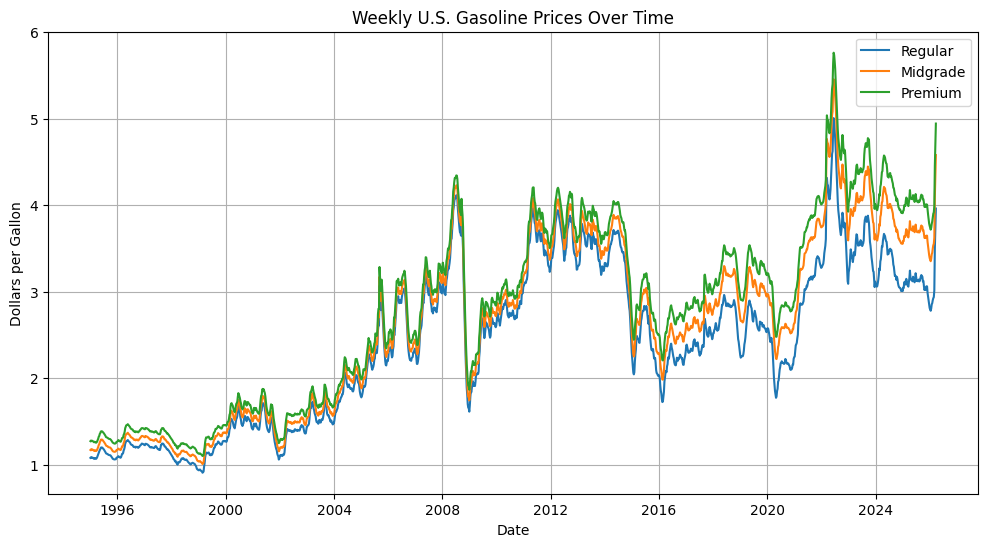

In [64]:

#Gasoline Price
plt.figure(figsize=(12,6))
plt.plot(final_df["Date"], final_df["Regular_Gasoline_Price"], label="Regular")
plt.plot(final_df["Date"], final_df["Midgrade_Gasoline_Price"], label="Midgrade")
plt.plot(final_df["Date"], final_df["Premium_Gasoline_Price"], label="Premium")

plt.title("Weekly U.S. Gasoline Prices Over Time")
plt.xlabel("Date")
plt.ylabel("Dollars per Gallon")
plt.legend()
plt.grid(True)
plt.show()

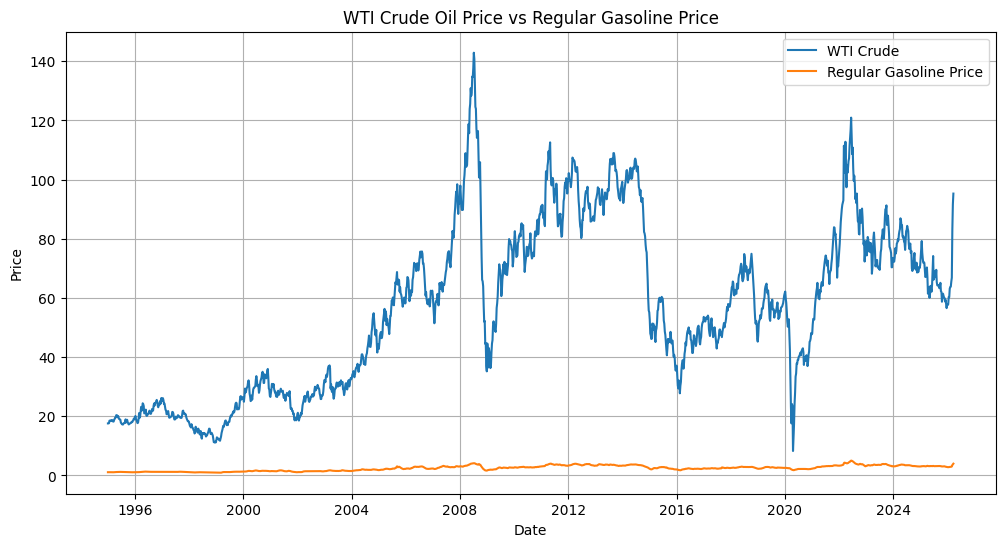

In [65]:
#Crude Oil vs Regular Gasoline Price

plt.figure(figsize=(12,6))
plt.plot(final_df["Date"], final_df["WTI_Crude"], label="WTI Crude")
plt.plot(final_df["Date"], final_df["Regular_Gasoline_Price"], label="Regular Gasoline Price")

plt.title("WTI Crude Oil Price vs Regular Gasoline Price")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.show()

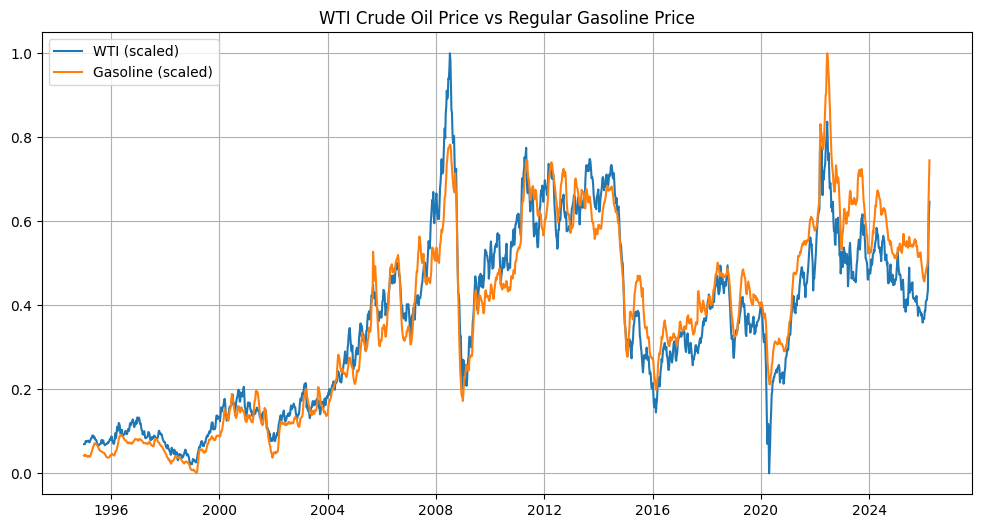

In [66]:
#Standardize and plot
scaler = MinMaxScaler()

scaled = scaler.fit_transform(
    final_df[["WTI_Crude", "Regular_Gasoline_Price"]]
)

scaled_df = pd.DataFrame(scaled, columns=["WTI", "Gasoline"])

plt.figure(figsize=(12,6))
plt.plot(final_df["Date"], scaled_df["WTI"], label="WTI (scaled)")
plt.plot(final_df["Date"], scaled_df["Gasoline"], label="Gasoline (scaled)")

plt.title("WTI Crude Oil Price vs Regular Gasoline Price")
plt.legend()
plt.grid(True)
plt.show()

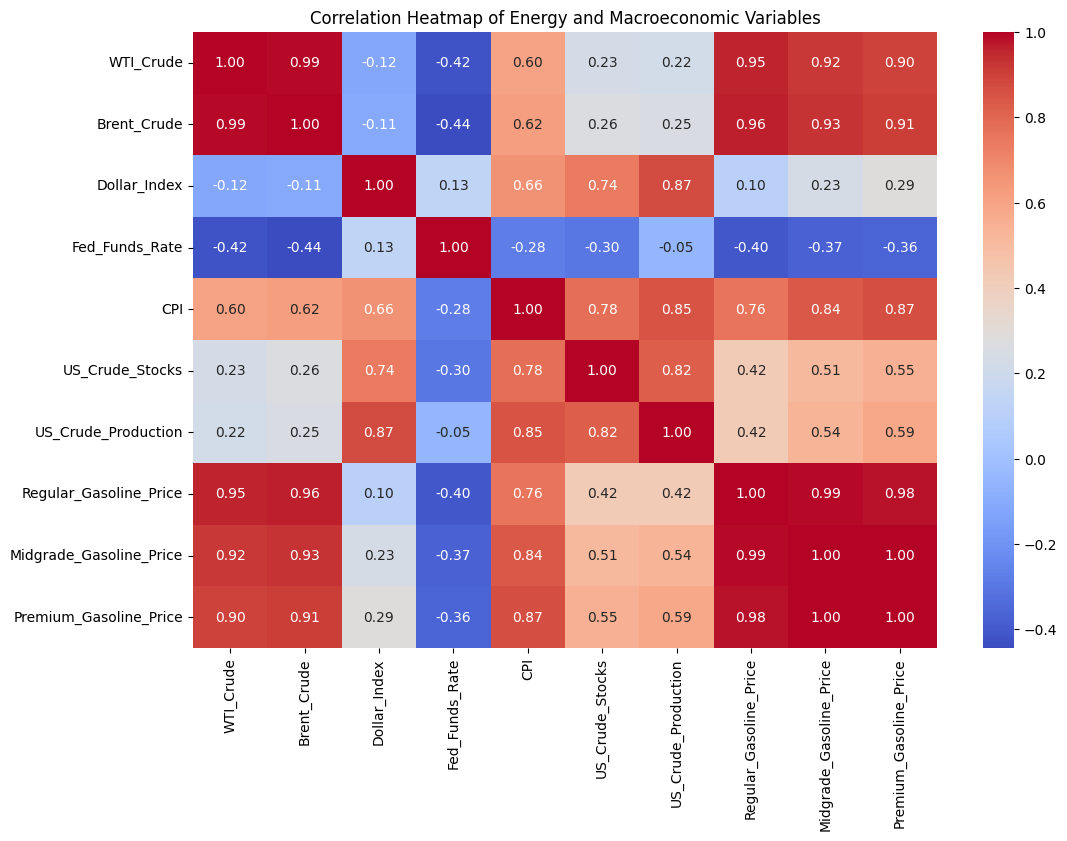

In [67]:
##Correlation Heatmap

import seaborn as sns

corr = final_df.drop(columns=["Date"]).corr()

plt.figure(figsize=(12,8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Energy and Macroeconomic Variables")
plt.show()

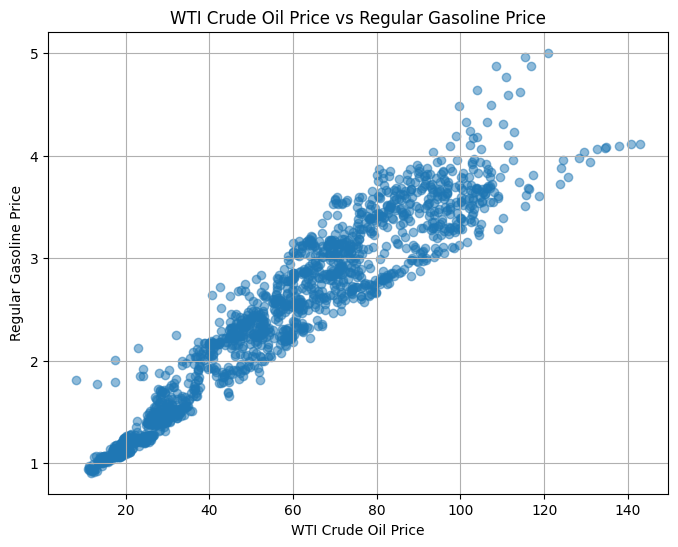

In [68]:
## Scatter Plot: WTI vs Regular Gasoline

plt.figure(figsize=(8,6))
plt.scatter(final_df["WTI_Crude"], final_df["Regular_Gasoline_Price"], alpha=0.5)

plt.title("WTI Crude Oil Price vs Regular Gasoline Price")
plt.xlabel("WTI Crude Oil Price")
plt.ylabel("Regular Gasoline Price")
plt.grid(True)
plt.show()

>> Since target variable is numeric: Regular_Gasoline_Price, Random Forest is a strong choice here because it can capture nonlinear relationships between crude oil prices, CPI, interest rates, dollar index, crude stocks, and gasoline prices without requiring heavy scaling.Random Forest is an ensemble machine learning model that builds many decision trees and averages their results for regression.
>> source:https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html#sklearn.ensemble.RandomForestRegressor

In [69]:
model_df = final_df.copy()

# Check the first few records
display(model_df.head())

# Check dataset structure
model_df.info()

,Date,WTI_Crude,Brent_Crude,Dollar_Index,Fed_Funds_Rate,CPI,US_Crude_Stocks,US_Crude_Production,Regular_Gasoline_Price,Midgrade_Gasoline_Price,Premium_Gasoline_Price
0,1995-01-02,17.572,16.074,101.4155,5.530,150.50,312846.0,6675.0,1.079,1.170,1.272
1,1995-01-09,17.572,16.074,101.4155,5.608,150.58,314560.0,6651.0,1.086,1.177,1.279
2,1995-01-16,17.650,16.292,101.4155,5.686,150.66,313278.0,6672.0,1.078,1.168,1.271
3,1995-01-23,18.502,17.008,101.4155,5.764,150.74,306864.0,6571.0,1.083,1.177,1.277
4,1995-01-30,18.346,16.784,101.4155,5.842,150.82,306583.0,6526.0,1.083,1.176,1.275


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1630 entries, 0 to 1629
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Date                     1630 non-null   datetime64[ns]
 1   WTI_Crude                1630 non-null   float64       
 2   Brent_Crude              1630 non-null   float64       
 3   Dollar_Index             1630 non-null   float64       
 4   Fed_Funds_Rate           1630 non-null   float64       
 5   CPI                      1630 non-null   float64       
 6   US_Crude_Stocks          1630 non-null   float64       
 7   US_Crude_Production      1630 non-null   float64       
 8   Regular_Gasoline_Price   1630 non-null   float64       
 9   Midgrade_Gasoline_Price  1630 non-null   float64       
 10  Premium_Gasoline_Price   1630 non-null   float64       
dtypes: datetime64[ns](1), float64(10)
memory usage: 140.2 KB


In [70]:

# Sort the data by date so the model uses older data firstand newer data later.

model_df = model_df.sort_values("Date").reset_index(drop=True)

display(model_df.head())

,Date,WTI_Crude,Brent_Crude,Dollar_Index,Fed_Funds_Rate,CPI,US_Crude_Stocks,US_Crude_Production,Regular_Gasoline_Price,Midgrade_Gasoline_Price,Premium_Gasoline_Price
0,1995-01-02,17.572,16.074,101.4155,5.530,150.50,312846.0,6675.0,1.079,1.170,1.272
1,1995-01-09,17.572,16.074,101.4155,5.608,150.58,314560.0,6651.0,1.086,1.177,1.279
2,1995-01-16,17.650,16.292,101.4155,5.686,150.66,313278.0,6672.0,1.078,1.168,1.271
3,1995-01-23,18.502,17.008,101.4155,5.764,150.74,306864.0,6571.0,1.083,1.177,1.277
4,1995-01-30,18.346,16.784,101.4155,5.842,150.82,306583.0,6526.0,1.083,1.176,1.275


### MOdel1: Without Lag features
Regular_Gasoline_Price is the target, so it cannot be inside features.
Midgrade_Gasoline_Price and Premium_Gasoline_Price should not be predictors because they are very closely related to regular gasoline price. Using them can cause data leakage.

In [71]:
model_df.columns

Index(['Date', 'WTI_Crude', 'Brent_Crude', 'Dollar_Index', 'Fed_Funds_Rate',
       'CPI', 'US_Crude_Stocks', 'US_Crude_Production',
       'Regular_Gasoline_Price', 'Midgrade_Gasoline_Price',
       'Premium_Gasoline_Price'],
      dtype='object')

In [72]:
# Option 1: Random Forest WITHOUT gasoline lag features
# Purpose: Understand how crude oil and economic indicators
# explain regular gasoline prices


# Create date-based features
model_df["Month"] = model_df["Date"].dt.month
model_df["Year"] = model_df["Date"].dt.year

# Target variable
target = "Regular_Gasoline_Price"

# Predictor variables WITHOUT gasoline lag features
features_no_lag = [
    "WTI_Crude",
    "Brent_Crude",
    "Dollar_Index",
    "Fed_Funds_Rate",
    "CPI",
    "US_Crude_Stocks",
    "US_Crude_Production",
    "Month",
    "Year"
]

X = model_df[features_no_lag]
y = model_df[target]

# Time-based train/test split
split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

date_test = model_df["Date"].iloc[split_index:]

# Build Random Forest model
rf_no_gas_lag = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_no_gas_lag.fit(X_train, y_train)

# Predict
rf_no_gas_lag_predictions = rf_no_gas_lag.predict(X_test)

# Evaluate
mae_no_gas_lag = mean_absolute_error(y_test, rf_no_gas_lag_predictions)
rmse_no_gas_lag = np.sqrt(mean_squared_error(y_test, rf_no_gas_lag_predictions))
r2_no_gas_lag = r2_score(y_test, rf_no_gas_lag_predictions)

print("Random Forest WITHOUT Gasoline Lag Features")
print("-" * 50)
print(f"MAE:  {mae_no_gas_lag:.4f}")
print(f"RMSE: {rmse_no_gas_lag:.4f}")
print(f"R²:   {r2_no_gas_lag:.4f}")

Random Forest WITHOUT Gasoline Lag Features
--------------------------------------------------
MAE:  0.3798
RMSE: 0.4434
R²:   0.4658


### Feature importance for Model1

,Feature,Importance
1,Brent_Crude,0.927119
0,WTI_Crude,0.033227
4,CPI,0.022456
6,US_Crude_Production,0.004304
7,Month,0.004098
3,Fed_Funds_Rate,0.003851
5,US_Crude_Stocks,0.002830
2,Dollar_Index,0.001419
8,Year,0.000696


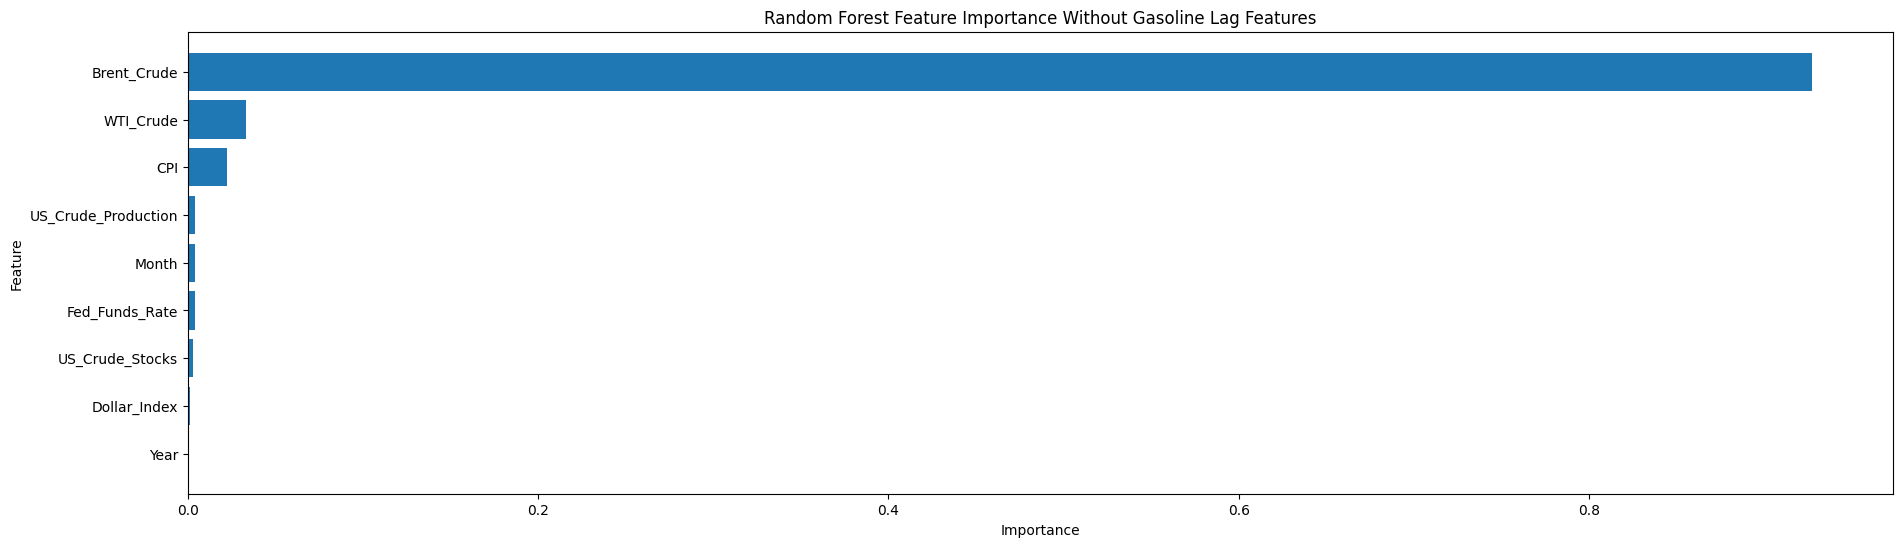

In [74]:
#Feature Importance 

rf_no_gas_lag_importance = pd.DataFrame({
    "Feature": features_no_lag,
    "Importance": rf_no_gas_lag.feature_importances_
}).sort_values(by="Importance", ascending=False)

display(rf_no_gas_lag_importance)

plt.figure(figsize=(22, 6))
plt.barh(
    rf_no_gas_lag_importance["Feature"],
    rf_no_gas_lag_importance["Importance"]
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance Without Gasoline Lag Features")
plt.gca().invert_yaxis()
plt.show()

>> This feature importance chart shows that Brent crude oil price is the most important factor in predicting U.S. regular gasoline prices. The model depends mostly on Brent_Crude, which means gasoline prices are strongly connected to global crude oil price changes. WTI_Crude and CPI have some influence, but their impact is much smaller compared to Brent crude. Other features like crude oil production, crude oil stocks, federal funds rate, dollar index, month, and year have very low importance in this model. This means that after crude oil price is included, these other variables do not add much extra prediction power.

,Date,Actual_Regular_Gasoline_Price,Predicted_Regular_Gasoline_Price
0,2019-12-30,2.571,2.587284
1,2020-01-06,2.578,2.579511
2,2020-01-13,2.570,2.547282
3,2020-01-20,2.537,2.531324
4,2020-01-27,2.506,2.515062


,Date,Actual_Regular_Gasoline_Price,Predicted_Regular_Gasoline_Price
321,2026-02-23,2.937,2.825471
322,2026-03-02,3.015,2.832013
323,2026-03-09,3.502,2.919354
324,2026-03-16,3.720,3.371345
325,2026-03-23,3.961,3.530423


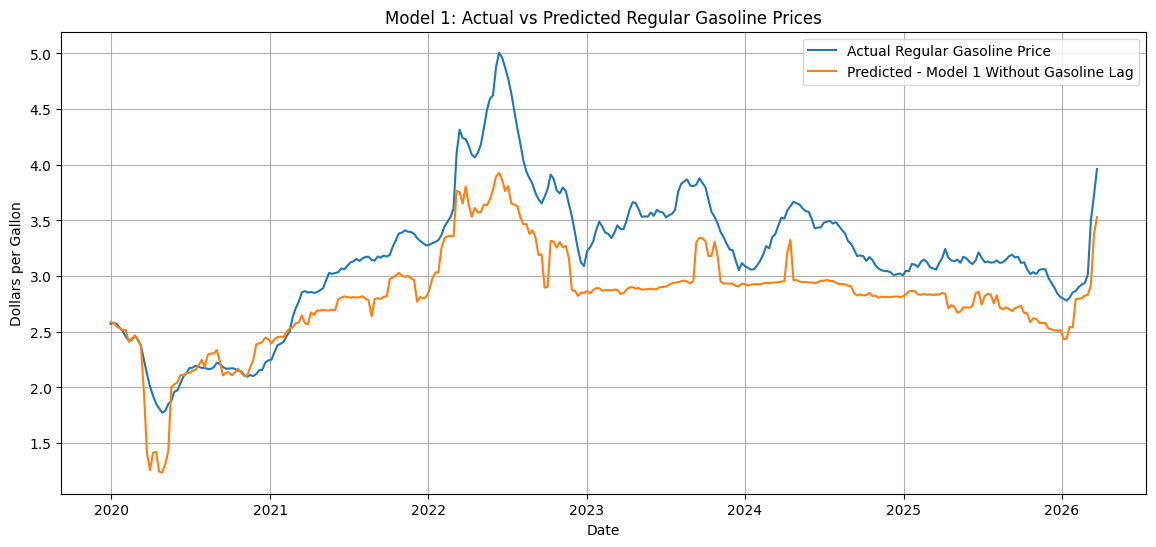

In [75]:
# ============================================================
# Model 1: Actual vs Predicted Plot
# Random Forest WITHOUT Gasoline Lag Features
# ============================================================

model1_prediction_df = pd.DataFrame({
    "Date": date_test.values,
    "Actual_Regular_Gasoline_Price": y_test.values,
    "Predicted_Regular_Gasoline_Price": rf_no_gas_lag_predictions
})

display(model1_prediction_df.head())
display(model1_prediction_df.tail())

plt.figure(figsize=(14, 6))

plt.plot(
    model1_prediction_df["Date"],
    model1_prediction_df["Actual_Regular_Gasoline_Price"],
    label="Actual Regular Gasoline Price"
)

plt.plot(
    model1_prediction_df["Date"],
    model1_prediction_df["Predicted_Regular_Gasoline_Price"],
    label="Predicted - Model 1 Without Gasoline Lag"
)

plt.title("Model 1: Actual vs Predicted Regular Gasoline Prices")
plt.xlabel("Date")
plt.ylabel("Dollars per Gallon")
plt.legend()
plt.grid(True)
plt.show()

### Model2:With Lag features - Time series prediction
This model can be considered a short-term time-series forecasting model because the data is arranged by date and the model uses lag-1 features, which represent the previous week’s values, to predict the current week’s regular gasoline price. 

>>We can use the shift() function in Pandas to automatically create new framings of time series problems given the desired length of input and output sequences.This would be a useful tool as it would allow us to explore different framings of a time series problem with machine learning algorithms to see which might result in better-performing models. source: https://machinelearningmastery.com/random-forest-for-time-series-forecasting/
>>shift() is useful because gasoline prices are time-dependent. This means the current week’s gasoline price may be influenced by previous weeks’ gasoline prices, crude oil prices, CPI, crude stocks, and other economic indicators.

In [76]:
# Option 2: Random Forest WITH Lag-1 for Each Major Variable
# Purpose: Short-term forecasting using previous week's data

# Copy final dataset
model_df = final_df.copy()

# Convert Date to datetime
model_df["Date"] = pd.to_datetime(model_df["Date"])

# Sort data by date so the previous row represents the previous week
model_df = model_df.sort_values("Date").reset_index(drop=True)


# Lag-1 means using the previous week's value to predict the current week's gasoline price.
# This is useful because gasoline prices usually change gradually over time.
# Create Lag-1 features for each major variable
model_df["Regular_Gasoline_Lag_1"] = model_df["Regular_Gasoline_Price"].shift(1)

model_df["WTI_Crude_Lag_1"] = model_df["WTI_Crude"].shift(1)
model_df["Brent_Crude_Lag_1"] = model_df["Brent_Crude"].shift(1)
model_df["Dollar_Index_Lag_1"] = model_df["Dollar_Index"].shift(1)
model_df["Fed_Funds_Rate_Lag_1"] = model_df["Fed_Funds_Rate"].shift(1)
model_df["CPI_Lag_1"] = model_df["CPI"].shift(1)
model_df["US_Crude_Stocks_Lag_1"] = model_df["US_Crude_Stocks"].shift(1)
model_df["US_Crude_Production_Lag_1"] = model_df["US_Crude_Production"].shift(1)

# Create date-based features
model_df["Month"] = model_df["Date"].dt.month
model_df["Year"] = model_df["Date"].dt.year

# Remove missing values created by shift()
model_df = model_df.dropna().reset_index(drop=True)

# Target variable
target = "Regular_Gasoline_Price"

# Predictor variables using Lag-1 features
features_lag1_all = [
    "Regular_Gasoline_Lag_1",
    "WTI_Crude_Lag_1",
    "Brent_Crude_Lag_1",
    "Dollar_Index_Lag_1",
    "Fed_Funds_Rate_Lag_1",
    "CPI_Lag_1",
    "US_Crude_Stocks_Lag_1",
    "US_Crude_Production_Lag_1",
    "Month",
    "Year"
]

X = model_df[features_lag1_all]
y = model_df[target]

# Time-based train/test split
# Since this is time-series data, we should not randomly split the data.
# Instead, the first 80% of the data is used for training,
# and the most recent 20% is used for testing.
split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

date_test = model_df["Date"].iloc[split_index:]

# Build Random Forest model
rf_lag1_all = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_lag1_all.fit(X_train, y_train)

# Predict
rf_lag1_all_predictions = rf_lag1_all.predict(X_test)

# Evaluate
mae_lag1_all = mean_absolute_error(y_test, rf_lag1_all_predictions)
rmse_lag1_all = np.sqrt(mean_squared_error(y_test, rf_lag1_all_predictions))
r2_lag1_all = r2_score(y_test, rf_lag1_all_predictions)

print("Random Forest WITH Lag-1 for Each Major Variable")
print("-" * 55)
print(f"MAE:  {mae_lag1_all:.4f}")
print(f"RMSE: {rmse_lag1_all:.4f}")
print(f"R²:   {r2_lag1_all:.4f}")

Random Forest WITH Lag-1 for Each Major Variable
-------------------------------------------------------
MAE:  0.0943
RMSE: 0.1754
R²:   0.9164


,Date,Actual_Regular_Gasoline_Price,Predicted_Regular_Gasoline_Price
0,2019-12-30,2.571,2.523218
1,2020-01-06,2.578,2.596657
2,2020-01-13,2.570,2.597864
3,2020-01-20,2.537,2.595284
4,2020-01-27,2.506,2.547005


,Date,Actual_Regular_Gasoline_Price,Predicted_Regular_Gasoline_Price
321,2026-02-23,2.937,2.893545
322,2026-03-02,3.015,2.904859
323,2026-03-09,3.502,2.985510
324,2026-03-16,3.720,3.413822
325,2026-03-23,3.961,3.714056


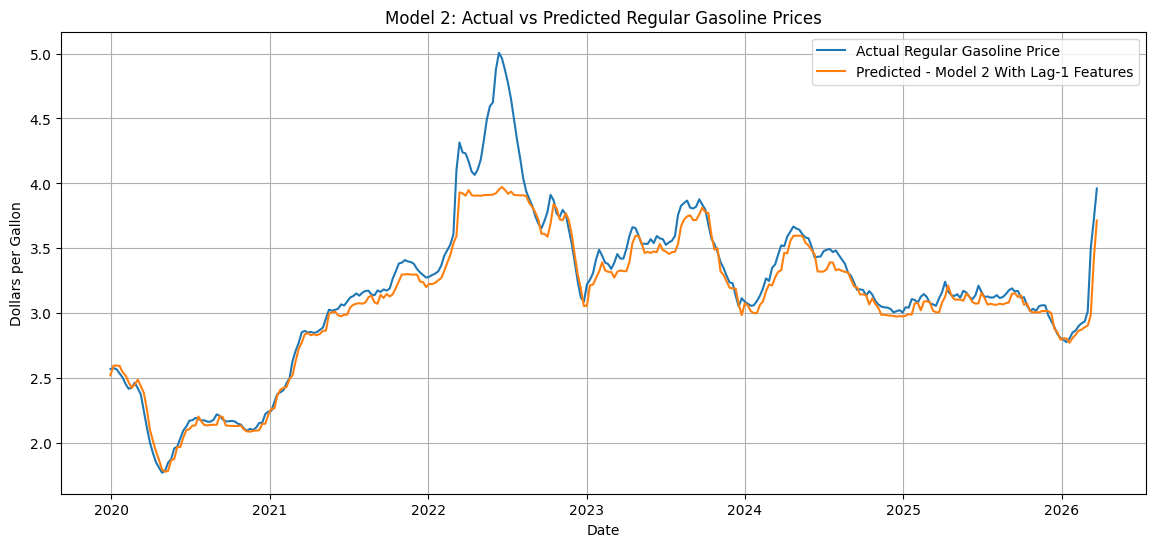

In [77]:
# ============================================================
# Model 2: Actual vs Predicted Plot
# Random Forest WITH Lag-1 Features
# ============================================================

model2_prediction_df = pd.DataFrame({
    "Date": date_test.values,
    "Actual_Regular_Gasoline_Price": y_test.values,
    "Predicted_Regular_Gasoline_Price": rf_lag1_all_predictions
})

display(model2_prediction_df.head())
display(model2_prediction_df.tail())

plt.figure(figsize=(14, 6))

plt.plot(
    model2_prediction_df["Date"],
    model2_prediction_df["Actual_Regular_Gasoline_Price"],
    label="Actual Regular Gasoline Price"
)

plt.plot(
    model2_prediction_df["Date"],
    model2_prediction_df["Predicted_Regular_Gasoline_Price"],
    label="Predicted - Model 2 With Lag-1 Features"
)

plt.title("Model 2: Actual vs Predicted Regular Gasoline Prices")
plt.xlabel("Date")
plt.ylabel("Dollars per Gallon")
plt.legend()
plt.grid(True)
plt.show()

### Feature importance of Model2 with lag 

,Feature,Importance
0,Regular_Gasoline_Lag_1,0.986588
2,Brent_Crude_Lag_1,0.011553
8,Month,0.000334
1,WTI_Crude_Lag_1,0.000305
7,US_Crude_Production_Lag_1,0.000294
5,CPI_Lag_1,0.000268
6,US_Crude_Stocks_Lag_1,0.000245
4,Fed_Funds_Rate_Lag_1,0.000203
3,Dollar_Index_Lag_1,0.000182
9,Year,0.000028


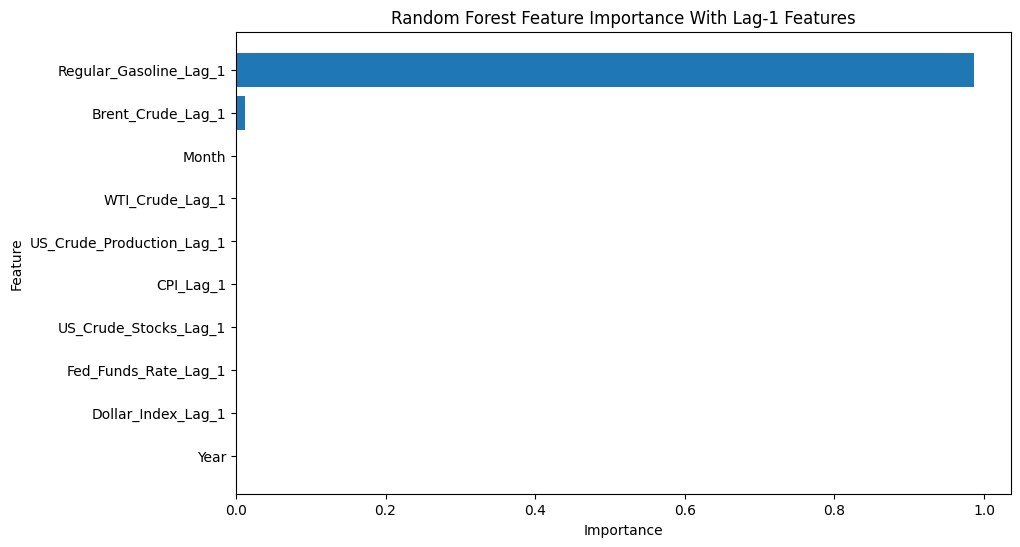

In [78]:
rf_lag1_all_importance = pd.DataFrame({
    "Feature": features_lag1_all,
    "Importance": rf_lag1_all.feature_importances_
}).sort_values(by="Importance", ascending=False)

display(rf_lag1_all_importance)

plt.figure(figsize=(10, 6))
plt.barh(
    rf_lag1_all_importance["Feature"],
    rf_lag1_all_importance["Importance"]
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance With Lag-1 Features")
plt.gca().invert_yaxis()
plt.show()

>>The above chart and plot shows the Random Forest feature importance after adding lag-1 features, which means the model is using the previous week’s values to predict the current gasoline price. The most important feature is Regular_Gasoline_Lag_1, with an importance of about 0.986, so the model is depending almost completely on last week’s gasoline price. This makes sense because gasoline prices usually change gradually from week to week, so the previous week’s price is the strongest clue for predicting the next value. Brent_Crude_Lag_1 has a small importance, while WTI crude, CPI, crude stocks, crude production, interest rate, dollar index, month, and year have very little impact. Overall, this chart shows that when lag features are included, the model relies mainly on recent gasoline price history rather than economic indicators. This improves prediction accuracy, but it also means the model is more focused on short-term price patterns.

>>Random Forest WITHOUT Gasoline Lag Features
>>--------------------------------------------------
>>MAE:  0.3796
>>
>>RMSE: 0.4439
>>
>>R²:   0.4645



>> Random Forest WITH Lag-1 for Each Major Variable
>>-------------------------------------------------------
>>MAE:  0.0943
>> 
>>RMSE: 0.1754
>> 
>>R²:   0.9164

### Actual VS Predicted table for both

In [79]:
# Create Actual vs Predicted Results Table


prediction_comparison = pd.DataFrame({
    "Date": date_test.values,
    "Actual_Regular_Gasoline_Price": y_test.values,
    "Prediction_No_Gas_Lag_Model": rf_no_gas_lag_predictions,
    "Prediction_Lag1_Model": rf_lag1_all_predictions
})

# Add error columns
prediction_comparison["Error_No_Gas_Lag_Model"] = (
    prediction_comparison["Actual_Regular_Gasoline_Price"] -
    prediction_comparison["Prediction_No_Gas_Lag_Model"]
)

prediction_comparison["Error_Lag1_Model"] = (
    prediction_comparison["Actual_Regular_Gasoline_Price"] -
    prediction_comparison["Prediction_Lag1_Model"]
)

# Add absolute error columns
prediction_comparison["Absolute_Error_No_Gas_Lag_Model"] = abs(
    prediction_comparison["Error_No_Gas_Lag_Model"]
)

prediction_comparison["Absolute_Error_Lag1_Model"] = abs(
    prediction_comparison["Error_Lag1_Model"]
)

display(prediction_comparison.head(20))

,Date,Actual_Regular_Gasoline_Price,Prediction_No_Gas_Lag_Model,Prediction_Lag1_Model,Error_No_Gas_Lag_Model,Error_Lag1_Model,Absolute_Error_No_Gas_Lag_Model,Absolute_Error_Lag1_Model
0,2019-12-30,2.571,2.587284,2.523218,-0.016284,0.047782,0.016284,0.047782
1,2020-01-06,2.578,2.579511,2.596657,-0.001511,-0.018657,0.001511,0.018657
2,2020-01-13,2.570,2.547282,2.597864,0.022718,-0.027864,0.022718,0.027864
3,2020-01-20,2.537,2.531324,2.595284,0.005676,-0.058284,0.005676,0.058284
4,2020-01-27,2.506,2.515062,2.547005,-0.009062,-0.041005,0.009062,0.041005
5,2020-02-03,2.455,2.517233,2.521658,-0.062233,-0.066658,0.062233,0.066658
6,2020-02-10,2.419,2.408498,2.468236,0.010502,-0.049236,0.010502,0.049236
7,2020-02-17,2.428,2.439959,2.427018,-0.011959,0.000982,0.011959,0.000982
8,2020-02-24,2.466,2.462560,2.452288,0.003440,0.013712,0.003440,0.013712
9,2020-03-02,2.423,2.430104,2.489256,-0.007104,-0.066256,0.007104,0.066256


### Plot

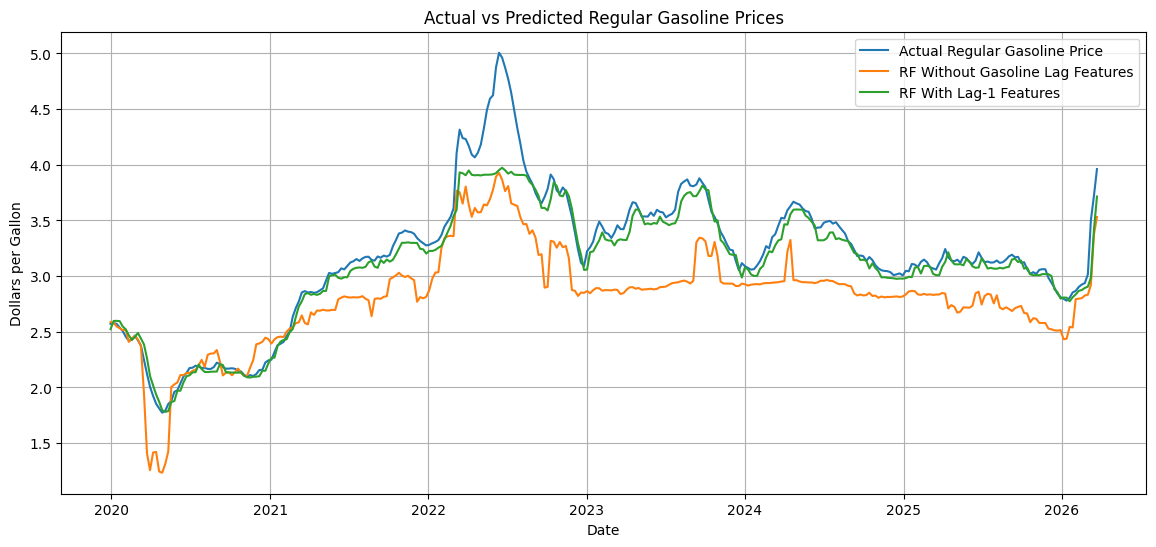

In [80]:
# Plot Actual vs Predicted Prices for Both Models


plt.figure(figsize=(14, 6))

plt.plot(
    prediction_comparison["Date"],
    prediction_comparison["Actual_Regular_Gasoline_Price"],
    label="Actual Regular Gasoline Price"
)

plt.plot(
    prediction_comparison["Date"],
    prediction_comparison["Prediction_No_Gas_Lag_Model"],
    label="RF Without Gasoline Lag Features"
)

plt.plot(
    prediction_comparison["Date"],
    prediction_comparison["Prediction_Lag1_Model"],
    label="RF With Lag-1 Features"
)

plt.title("Actual vs Predicted Regular Gasoline Prices")
plt.xlabel("Date")
plt.ylabel("Dollars per Gallon")
plt.legend()
plt.grid(True)
plt.show()

>>The plot compares the actual gasoline price with the predictions from two Random Forest models. The blue line shows the real gasoline price, the orange line shows the model without gasoline lag features, and the green line shows the model with Lag-1 features. The green line follows the actual price much more closely, which means the Lag-1 model is better for short-term forecasting. This happens because last week’s gasoline price is very useful for predicting this week’s price. The orange line does not follow the actual price as well, especially during large changes like the 2022 price spike, because it does not use recent gasoline price history. This shows that crude oil prices and economic indicators are helpful, but they are not enough by themselves to capture short-term gasoline price movements.

Lag features were introduced because gasoline price data is time-based, and this week’s price is often strongly related to previous weeks’ prices. Instead of using only current features such as WTI crude, Brent crude, CPI, crude stocks, production, and interest rates, lag features allow the model to use information that would already be available from the past, such as last week’s gasoline price or last week’s crude oil price. The downside is that when gasoline lag features are included, the model may depend heavily on the previous week’s gasoline price because gasoline prices usually change gradually. So, the lag model is better for short-term forecasting, while the model without gasoline lag features is better for understanding how crude oil, supply, and economic indicators relate to gasoline prices.

In [81]:
model_df.tail()

,Date,WTI_Crude,Brent_Crude,Dollar_Index,Fed_Funds_Rate,CPI,US_Crude_Stocks,US_Crude_Production,Regular_Gasoline_Price,Midgrade_Gasoline_Price,...,Regular_Gasoline_Lag_1,WTI_Crude_Lag_1,Brent_Crude_Lag_1,Dollar_Index_Lag_1,Fed_Funds_Rate_Lag_1,CPI_Lag_1,US_Crude_Stocks_Lag_1,US_Crude_Production_Lag_1,Month,Year
1624,2026-02-23,65.514,71.874,117.94934,3.64,329.58475,435804.0,13702.0,2.937,3.553,...,2.924,63.7825,70.620,117.511275,3.64,328.87650,419815.0,13735.0,2,2026
1625,2026-03-02,66.822,72.424,118.02176,3.64,330.29300,439279.0,13696.0,3.015,3.623,...,2.937,65.5140,71.874,117.949340,3.64,329.58475,435804.0,13702.0,3,2026
1626,2026-03-09,83.072,88.704,119.41580,3.64,330.71580,443103.0,13678.0,3.502,4.098,...,3.015,66.8220,72.424,118.021760,3.64,330.29300,439279.0,13696.0,3,2026
1627,2026-03-16,91.598,97.494,119.69710,3.64,331.13860,449259.0,13668.0,3.720,4.343,...,3.502,83.0720,88.704,119.415800,3.64,330.71580,443103.0,13678.0,3,2026
1628,2026-03-23,95.256,111.948,120.03068,3.64,331.56140,456185.0,13657.0,3.961,4.579,...,3.720,91.5980,97.494,119.697100,3.64,331.13860,449259.0,13668.0,3,2026


In [82]:
# ============================================================
# Model 2: Save Actual and Predicted Values in a DataFrame
# ============================================================

model2_prediction_df = pd.DataFrame({
    "Date": date_test.values,
    "Actual_Regular_Gasoline_Price": y_test.values,
    "Predicted_Regular_Gasoline_Price_Model2": rf_lag1_all_predictions
})

# Calculate prediction error
model2_prediction_df["Error"] = (
    model2_prediction_df["Actual_Regular_Gasoline_Price"] -
    model2_prediction_df["Predicted_Regular_Gasoline_Price_Model2"]
)

# Calculate absolute error
model2_prediction_df["Absolute_Error"] = abs(model2_prediction_df["Error"])

# Display first few rows of test-period predictions
display(model2_prediction_df.head())

# Display last few rows of test-period predictions
display(model2_prediction_df.tail())

,Date,Actual_Regular_Gasoline_Price,Predicted_Regular_Gasoline_Price_Model2,Error,Absolute_Error
0,2019-12-30,2.571,2.523218,0.047782,0.047782
1,2020-01-06,2.578,2.596657,-0.018657,0.018657
2,2020-01-13,2.570,2.597864,-0.027864,0.027864
3,2020-01-20,2.537,2.595284,-0.058284,0.058284
4,2020-01-27,2.506,2.547005,-0.041005,0.041005


,Date,Actual_Regular_Gasoline_Price,Predicted_Regular_Gasoline_Price_Model2,Error,Absolute_Error
321,2026-02-23,2.937,2.893545,0.043455,0.043455
322,2026-03-02,3.015,2.904859,0.110141,0.110141
323,2026-03-09,3.502,2.985510,0.516490,0.516490
324,2026-03-16,3.720,3.413822,0.306178,0.306178
325,2026-03-23,3.961,3.714056,0.246944,0.246944


>>The model was evaluated using a time-based train-test split. The first 80% of the data was used for training, and the most recent 20% was used for testing. Since the dataset ends on March 23, 2026, the model predictions also end on that date. Therefore, the model results represent historical test-period predictions rather than true future forecasts beyond the available dataset. The Lag-1 model predicts one week ahead by using previous-week values as inputs.

In [83]:
# ============================================================
# Plot Test Period Forecast: Actual vs Predicted for Model 2
# Random Forest With Lag-1 Features
# ============================================================

# Create Model 2 prediction dataframe
model2_prediction_df = pd.DataFrame({
    "Date": date_test.values,
    "Actual_Regular_Gasoline_Price": y_test.values,
    "Predicted_Regular_Gasoline_Price": rf_lag1_all_predictions
})

# Calculate error
model2_prediction_df["Error"] = (
    model2_prediction_df["Actual_Regular_Gasoline_Price"] -
    model2_prediction_df["Predicted_Regular_Gasoline_Price"]
)

# Calculate absolute error
model2_prediction_df["Absolute_Error"] = abs(model2_prediction_df["Error"])

# Check the test-period prediction data
display(model2_prediction_df.head())
display(model2_prediction_df.tail())

# Check test period range
print("Test period starts:", model2_prediction_df["Date"].min())
print("Test period ends:", model2_prediction_df["Date"].max())
print("Number of test records:", len(model2_prediction_df))

,Date,Actual_Regular_Gasoline_Price,Predicted_Regular_Gasoline_Price,Error,Absolute_Error
0,2019-12-30,2.571,2.523218,0.047782,0.047782
1,2020-01-06,2.578,2.596657,-0.018657,0.018657
2,2020-01-13,2.570,2.597864,-0.027864,0.027864
3,2020-01-20,2.537,2.595284,-0.058284,0.058284
4,2020-01-27,2.506,2.547005,-0.041005,0.041005


,Date,Actual_Regular_Gasoline_Price,Predicted_Regular_Gasoline_Price,Error,Absolute_Error
321,2026-02-23,2.937,2.893545,0.043455,0.043455
322,2026-03-02,3.015,2.904859,0.110141,0.110141
323,2026-03-09,3.502,2.985510,0.516490,0.516490
324,2026-03-16,3.720,3.413822,0.306178,0.306178
325,2026-03-23,3.961,3.714056,0.246944,0.246944


Test period starts: 2019-12-30 00:00:00
Test period ends: 2026-03-23 00:00:00
Number of test records: 326


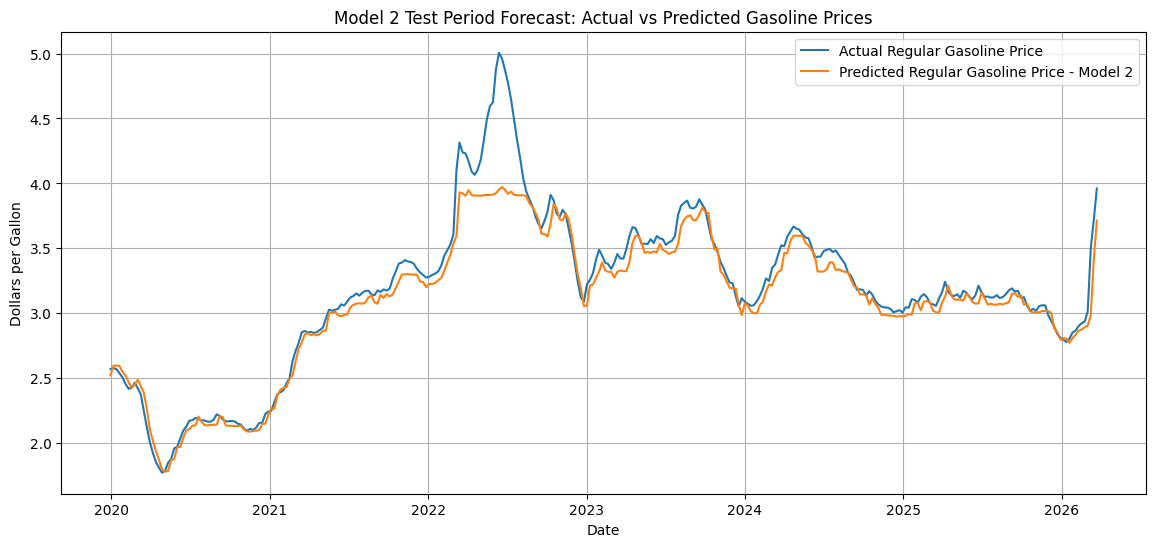

In [84]:
# ============================================================
# Actual vs Predicted Plot for Model 2
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    model2_prediction_df["Date"],
    model2_prediction_df["Actual_Regular_Gasoline_Price"],
    label="Actual Regular Gasoline Price"
)

plt.plot(
    model2_prediction_df["Date"],
    model2_prediction_df["Predicted_Regular_Gasoline_Price"],
    label="Predicted Regular Gasoline Price - Model 2"
)

plt.title("Model 2 Test Period Forecast: Actual vs Predicted Gasoline Prices")
plt.xlabel("Date")
plt.ylabel("Dollars per Gallon")
plt.legend()
plt.grid(True)
plt.show()

## Optional Model - XGBoost

In [104]:
# ============================================================
# Model 3: XGBoost for better indicators
# Purpose: Improved long-term explanatory model
# Uses same train/test split logic as RF Model 1
# ============================================================

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Copy cleaned dataset
model3_df = model_df.copy()

# Make sure Date is datetime and sorted
model3_df["Date"] = pd.to_datetime(model3_df["Date"])
model3_df = model3_df.sort_values("Date").reset_index(drop=True)

# Create date-based features
model3_df["Month"] = model3_df["Date"].dt.month
model3_df["Year"] = model3_df["Date"].dt.year

# Target variable
target_3 = "Regular_Gasoline_Price"

# Predictor variables WITHOUT gasoline lag features
features_3 = [
    "WTI_Crude",
    "Brent_Crude",
    "Dollar_Index",
    "Fed_Funds_Rate",
    "CPI",
    "US_Crude_Stocks",
    "US_Crude_Production",
    "Month",
    "Year"
]

X_3 = model3_df[features_3]
y_3 = model3_df[target_3]

# Same time-based 80/20 train/test split
split_index_3 = int(len(model3_df) * 0.80)

X_train_3 = X_3.iloc[:split_index_3]
X_test_3 = X_3.iloc[split_index_3:]

y_train_3 = y_3.iloc[:split_index_3]
y_test_3 = y_3.iloc[split_index_3:]

date_test_3 = model3_df["Date"].iloc[split_index_3:]

# Build XGBoost model
xgb_model_3 = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=4,
    min_child_weight=3,
    subsample=0.85,
    colsample_bytree=0.85,
    objective="reg:squarederror",
    random_state=42
)

# Train model
xgb_model_3.fit(X_train_3, y_train_3)

# Predict
xgb_predictions_3 = xgb_model_3.predict(X_test_3)

# Evaluate
mae_xgb_3 = mean_absolute_error(y_test_3, xgb_predictions_3)
rmse_xgb_3 = np.sqrt(mean_squared_error(y_test_3, xgb_predictions_3))
r2_xgb_3 = r2_score(y_test_3, xgb_predictions_3)

print("Model 3: XGBoost WITHOUT Gasoline Lag Features")
print("-" * 60)
print(f"MAE: {mae_xgb_3:.4f}")
print(f"RMSE: {rmse_xgb_3:.4f}")
print(f"R²: {r2_xgb_3:.4f}")

Model 3: XGBoost WITHOUT Gasoline Lag Features
------------------------------------------------------------
MAE: 0.3742
RMSE: 0.4213
R²: 0.5177


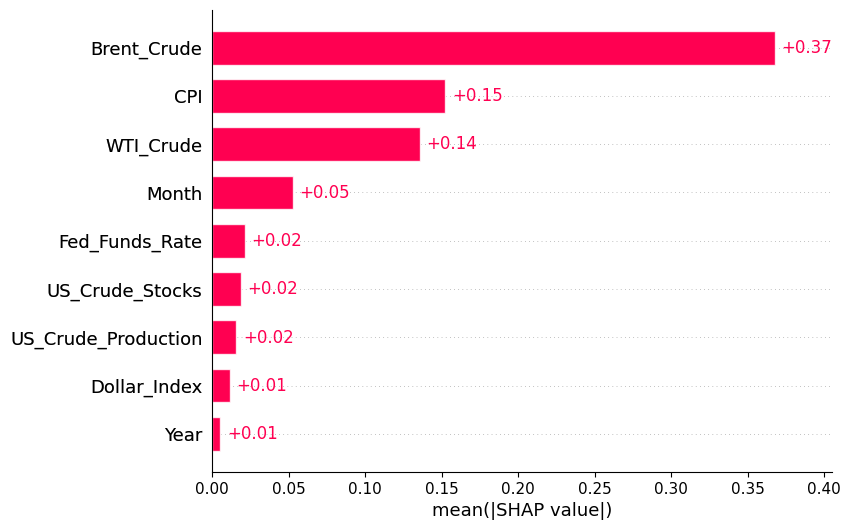

In [108]:
# ============================================================
# SHAP Feature Importance for Model 3: XGBoost No-Lag Model
# ============================================================

import shap

explainer_3 = shap.Explainer(xgb_model_3, X_train_3)

shap_values_3 = explainer_3(X_test_3)

shap.plots.bar(shap_values_3, max_display=10)

>>This SHAP feature importance plot explains which variables had the strongest impact on the Model 3 XGBoost no-lag prediction. Since this model does not use the previous week’s gasoline price, the plot shows the importance of external market factors. Brent crude oil is the most important factor, meaning changes in Brent crude price had the strongest influence on predicted gasoline prices. CPI (Consumer Price Index) and WTI crude oil are the next most important factors, showing that inflation and crude oil market prices also strongly affect gasoline price movement. Month, Federal Funds Rate, crude stocks, crude production, Dollar Index, and year had smaller impacts, but they still helped the model understand seasonal patterns, economic conditions, and supply-side changes. Overall, this plot supports the business conclusion that gasoline prices are mainly driven by crude oil prices, inflation, and broader supply/economic conditions.

,Date,Actual_Regular_Gasoline_Price,Predicted_XGBoost_Model_3
0,2019-12-30,2.571,2.609922
1,2020-01-06,2.578,2.526940
2,2020-01-13,2.570,2.468293
3,2020-01-20,2.537,2.421229
4,2020-01-27,2.506,2.421540


,Date,Actual_Regular_Gasoline_Price,Predicted_XGBoost_Model_3
321,2026-02-23,2.937,2.658728
322,2026-03-02,3.015,2.736476
323,2026-03-09,3.502,2.984679
324,2026-03-16,3.720,3.354531
325,2026-03-23,3.961,3.529269


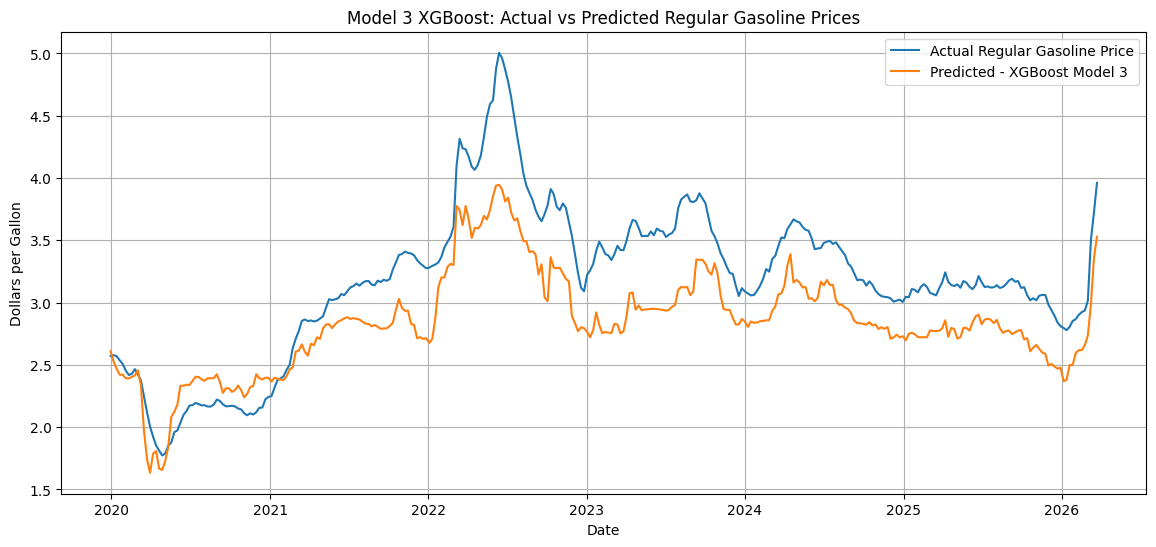

In [110]:
# ============================================================
# Model 3 Actual vs Predicted Plot
# ============================================================

model3_prediction_df = pd.DataFrame({
    "Date": date_test_3.values,
    "Actual_Regular_Gasoline_Price": y_test_3.values,
    "Predicted_XGBoost_Model_3": xgb_predictions_3
})

display(model3_prediction_df.head())
display(model3_prediction_df.tail())

plt.figure(figsize=(14, 6))

plt.plot(
    model3_prediction_df["Date"],
    model3_prediction_df["Actual_Regular_Gasoline_Price"],
    label="Actual Regular Gasoline Price"
)

plt.plot(
    model3_prediction_df["Date"],
    model3_prediction_df["Predicted_XGBoost_Model_3"],
    label="Predicted - XGBoost Model 3"
)

plt.title("Model 3 XGBoost: Actual vs Predicted Regular Gasoline Prices")
plt.xlabel("Date")
plt.ylabel("Dollars per Gallon")
plt.legend()
plt.grid(True)
plt.show()

>> In this version, the model predicts regular gasoline prices using external market factors such as WTI crude oil, Brent crude oil, Dollar Index, Federal Funds Rate, CPI, crude oil stocks, crude oil production, month, and year. The prediction line follows the general direction of gasoline prices, especially the major increases and decreases from 2020 to 2026. However, the model underpredicts some high-price periods, especially around 2022, when gasoline prices increased sharply.
>> XGBoost is a good long-term explanatory model because it shows how outside economic and energy factors influence gasoline prices, but it should not be expected to perfectly predict sudden market shocks. For short-term weekly forecasting, the lag-based model is stronger, but for long-term business understanding, this XGBoost no-lag model gives a better explanation of market drivers.

### Final Model Comaprison


In [111]:
# ============================================================
# Final Model Evaluation Comparison Table
# ============================================================

all_model_evaluations = pd.DataFrame({
    "Model": [
        "Model 1: Random Forest Without Lag",
        "Model 2: Random Forest With Lag-1",
        "Model 3: XGBoost Without Lag"
    ],
    "Purpose": [
        "Baseline long-term explanatory model",
        "Short-term weekly forecasting model",
        "Improved long-term explanatory model"
    ],
    "MAE": [
        mae_no_gas_lag,
        mae_lag1_all,
        mae_xgb_3
    ],
    "RMSE": [
        rmse_no_gas_lag,
        rmse_lag1_all,
        rmse_xgb_3
    ],
    "R2": [
        r2_no_gas_lag,
        r2_lag1_all,
        r2_xgb_3
    ]
})

display(all_model_evaluations)

,Model,Purpose,MAE,RMSE,R2
0,Model 1: Random Forest Without Lag,Baseline long-term explanatory model,0.379786,0.443364,0.465756
1,Model 2: Random Forest With Lag-1,Short-term weekly forecasting model,0.094267,0.175398,0.916388
2,Model 3: XGBoost Without Lag,Improved long-term explanatory model,0.374157,0.421262,0.517692


>>MAE (Mean Absolute Error)shows the average prediction error in the original unit,RMSE (Root Mean Squared Error)also shows prediction error in dollars per gallon,R² shows how much of the gasoline price variation the model explains.
>>
>>The above table compares the three models using MAE, RMSE, and R². Model 1, Random Forest without lag, was used as the baseline long-term explanatory model. Its R² value is 0.4658, which means it explains about 46.6% of the gasoline price variation using external market variables. Model 2, Random Forest with Lag-1, performed the best with the lowest MAE 0.0943, lowest RMSE 0.1754, and highest R² 0.9164. This means it is the strongest model for short-term weekly forecasting because gasoline prices are highly influenced by the previous week’s price. Model 3, XGBoost without lag, improved slightly over Model 1, with R² increasing to 0.5177 and RMSE decreasing to 0.4213. This shows that XGBoost captured some additional nonlinear patterns from crude oil and economic indicators (for better factors).

In [113]:

# ============================================================
# MAPE Scores for All Three Models
# ============================================================

mape_model_1 = mean_absolute_percentage_error(y_test, rf_no_gas_lag_predictions) * 100
mape_model_2 = mean_absolute_percentage_error(y_test, rf_lag1_all_predictions) * 100
mape_model_3 = mean_absolute_percentage_error(y_test_3, xgb_predictions_3) * 100

print("MAPE Scores")
print("-" * 40)
print(f"Model 1 Random Forest Without Lag MAPE: {mape_model_1:.2f}%")
print(f"Model 2 Random Forest With Lag-1 MAPE: {mape_model_2:.2f}%")
print(f"Model 3 XGBoost Without Lag MAPE: {mape_model_3:.2f}%")

MAPE Scores
----------------------------------------
Model 1 Random Forest Without Lag MAPE: 11.43%
Model 2 Random Forest With Lag-1 MAPE: 2.64%
Model 3 XGBoost Without Lag MAPE: 11.30%


>>MAPE (Mean Absolute Percentage Error)shows the average error as a percentage, was added to show the model error as a percentage, which makes the results easier to understand from a business perspective. Model 1, the Random Forest model without lag features, had a MAPE of 11.43%, meaning its predictions were off by about 11.43% on average. Model 3, the XGBoost model without lag features, had a similar MAPE of 11.30%, showing a slight improvement over the baseline no-lag model. These two models are useful for long-term explanation because they use external market and economic indicators instead of depending on previous gasoline prices. Model 2, the Random Forest model with lag-1 features, had the lowest MAPE at 2.64%, making it the best model for short-term weekly forecasting.
>>

#### Option 4: LSTM Time-Series Forecasting Model
#### Purpose: Improve short-term gasoline price prediction by learning from multiple previous weeks
 Unlike Random Forest with Lag-1 previous week's data, LSTM uses a sequence of past observations to predict the current price.

In [123]:
# Option 4: LSTM Time-Series Forecasting Model
# Purpose: Short-term time-series forecasting using multiple previous weeks of data

# Copy final dataset
lstm_df = final_df.copy()

# Convert Date to datetime
lstm_df["Date"] = pd.to_datetime(lstm_df["Date"])

# Sort by date
lstm_df = lstm_df.sort_values("Date").reset_index(drop=True)

# Select features for LSTM
# LSTM will use current and historical patterns from these variables
lstm_features = [
    "Regular_Gasoline_Price",
    "WTI_Crude",
    "Brent_Crude",
    "Dollar_Index",
    "Fed_Funds_Rate",
    "CPI",
    "US_Crude_Stocks",
    "US_Crude_Production"
]

# Keep only selected columns and remove missing values
lstm_df = lstm_df[["Date"] + lstm_features].dropna().reset_index(drop=True)

# Scale the data because LSTM models work better with normalized values
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(lstm_df[lstm_features])

# Sequence length means how many previous weeks the model will look at
# Example: 12 means the model uses the past 12 weeks to predict the next week
sequence_length = 12

X_lstm = []
y_lstm = []
dates_lstm = []

# Create sequences
for i in range(sequence_length, len(scaled_data)):
    X_lstm.append(scaled_data[i-sequence_length:i])
    
    # Target is Regular_Gasoline_Price, which is the first column in lstm_features
    y_lstm.append(scaled_data[i, 0])
    
    dates_lstm.append(lstm_df["Date"].iloc[i])

X_lstm = np.array(X_lstm)
y_lstm = np.array(y_lstm)
dates_lstm = np.array(dates_lstm)

# Time-based train/test split
split_index = int(len(X_lstm) * 0.80)

X_train_lstm = X_lstm[:split_index]
X_test_lstm = X_lstm[split_index:]

y_train_lstm = y_lstm[:split_index]
y_test_lstm = y_lstm[split_index:]

date_test_lstm = dates_lstm[split_index:]

# Build LSTM model
lstm_model = Sequential()

lstm_model.add(
    LSTM(
        units=64,
        return_sequences=True,
        input_shape=(X_train_lstm.shape[1], X_train_lstm.shape[2])
    )
)

lstm_model.add(Dropout(0.2))

lstm_model.add(
    LSTM(
        units=32,
        return_sequences=False
    )
)

lstm_model.add(Dropout(0.2))

lstm_model.add(Dense(16, activation="relu"))
lstm_model.add(Dense(1))

# Compile model
lstm_model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

# Stop training early if validation loss stops improving
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train model
history = lstm_model.fit(
    X_train_lstm,
    y_train_lstm,
    epochs=100,
    batch_size=16,
    validation_split=0.20,
    callbacks=[early_stop],
    verbose=1
)

# Predict scaled values
lstm_predictions_scaled = lstm_model.predict(X_test_lstm)

# To inverse transform, create empty arrays with same number of features
# because scaler expects all original feature columns
y_test_full = np.zeros((len(y_test_lstm), len(lstm_features)))
pred_full = np.zeros((len(lstm_predictions_scaled), len(lstm_features)))

# Put actual and predicted gasoline price values into the first column
y_test_full[:, 0] = y_test_lstm
pred_full[:, 0] = lstm_predictions_scaled.flatten()

# Convert scaled values back to original gasoline price scale
y_test_lstm_actual = scaler.inverse_transform(y_test_full)[:, 0]
lstm_predictions = scaler.inverse_transform(pred_full)[:, 0]

# Evaluate LSTM
mae_lstm = mean_absolute_error(y_test_lstm_actual, lstm_predictions)
rmse_lstm = np.sqrt(mean_squared_error(y_test_lstm_actual, lstm_predictions))
r2_lstm = r2_score(y_test_lstm_actual, lstm_predictions)

print("LSTM Time-Series Forecasting Model")
print("-" * 45)
print(f"MAE:  {mae_lstm:.4f}")
print(f"RMSE: {rmse_lstm:.4f}")
print(f"R²:   {r2_lstm:.4f}")

Epoch 1/100
65/65 [==============================] - 12s 58ms/step - loss: 0.0095 - val_loss: 0.0010
Epoch 2/100
65/65 [==============================] - 1s 20ms/step - loss: 0.0049 - val_loss: 0.0018
Epoch 3/100
65/65 [==============================] - 1s 21ms/step - loss: 0.0036 - val_loss: 0.0026
Epoch 4/100
65/65 [==============================] - 1s 18ms/step - loss: 0.0031 - val_loss: 0.0020
Epoch 5/100
65/65 [==============================] - 1s 21ms/step - loss: 0.0031 - val_loss: 0.0056
Epoch 6/100
65/65 [==============================] - 2s 26ms/step - loss: 0.0029 - val_loss: 0.0030
Epoch 7/100
65/65 [==============================] - 1s 20ms/step - loss: 0.0025 - val_loss: 0.0054
Epoch 8/100
65/65 [==============================] - 1s 20ms/step - loss: 0.0021 - val_loss: 0.0054
Epoch 9/100
65/65 [==============================] - 1s 21ms/step - loss: 0.0020 - val_loss: 0.0085
Epoch 10/100
65/65 [==============================] - 1s 20ms/step - loss: 0.0020 - val_loss: 0.007

>>. The R² value of 0.6622 means the LSTM explains about 66% of the variation in gasoline prices. The LSTM produced an MAE of 0.2627, RMSE of 0.3526, and R² of 0.6622. This shows that the model was able to capture general time-series patterns, but it did not fully improve prediction performance compared to the Random Forest lag model. One possible reason is that gasoline price peaks are often caused by sudden external events like the past week's data in RF.

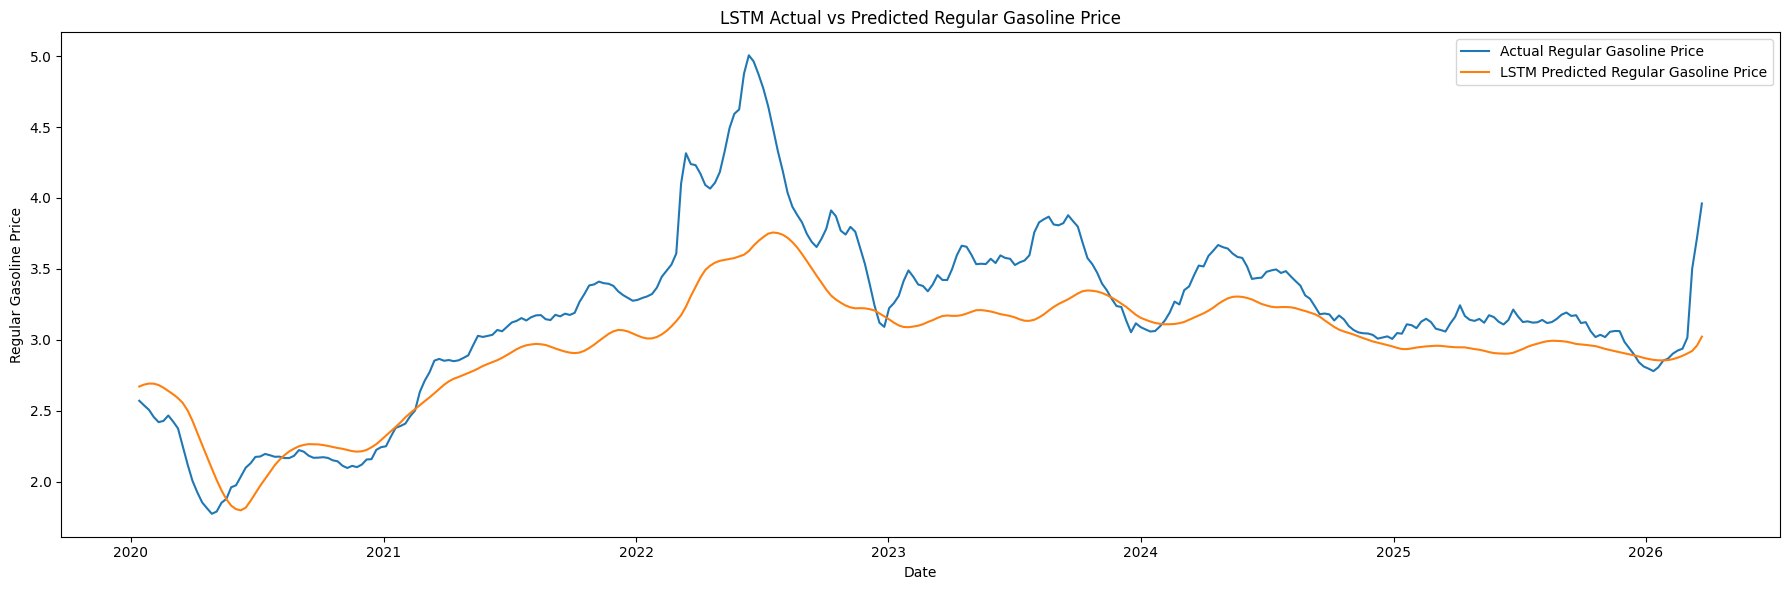

In [124]:
#LSTM -actual vs predicted:

plt.figure(figsize=(18, 6))

plt.plot(
    date_test_lstm,
    y_test_lstm_actual,
    label="Actual Regular Gasoline Price"
)

plt.plot(
    date_test_lstm,
    lstm_predictions,
    label="LSTM Predicted Regular Gasoline Price"
)

plt.xlabel("Date")
plt.ylabel("Regular Gasoline Price")
plt.title("LSTM Actual vs Predicted Regular Gasoline Price")
plt.legend()
plt.tight_layout()
plt.show()

#### Option 5 - SARIMAX Model - for Time Series

In [132]:
# Option 3: SARIMAX Time-Series Forecasting Model
# Improved SARIMAX Model with Scaled External Variables
# Purpose: Traditional time-series forecasting using gasoline price history
# and normalized economic indicators

warnings.filterwarnings("ignore")

# Copy final dataset
sarimax_df = final_df.copy()

# Convert Date to datetime
sarimax_df["Date"] = pd.to_datetime(sarimax_df["Date"])

# Sort by date
sarimax_df = sarimax_df.sort_values("Date").reset_index(drop=True)

# Target variable
target = "Regular_Gasoline_Price"

# External predictor variables
exog_features = [
    "WTI_Crude",
    "Brent_Crude",
    "Dollar_Index",
    "Fed_Funds_Rate",
    "CPI",
    "US_Crude_Stocks",
    "US_Crude_Production"
]

# Keep required columns and remove missing values
sarimax_df = sarimax_df[["Date", target] + exog_features].dropna().reset_index(drop=True)

# Set Date as index
sarimax_df = sarimax_df.set_index("Date")

# Define y and X
y = sarimax_df[target]
X = sarimax_df[exog_features]

# Time-based train/test split
split_index = int(len(sarimax_df) * 0.80)

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

# Scale external variables
# SARIMAX can behave poorly when external variables have very different scales
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=exog_features,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=exog_features,
    index=X_test.index
)

# Build improved SARIMAX model
# A simpler order is used to reduce unstable forecasting behavior
sarimax_model = SARIMAX(
    y_train,
    exog=X_train_scaled,
    order=(1, 1, 0),
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Train model
sarimax_result = sarimax_model.fit(disp=False)

# Forecast test period
sarimax_predictions = sarimax_result.forecast(
    steps=len(y_test),
    exog=X_test_scaled
)

# Evaluate
mae_sarimax = mean_absolute_error(y_test, sarimax_predictions)
rmse_sarimax = np.sqrt(mean_squared_error(y_test, sarimax_predictions))
r2_sarimax = r2_score(y_test, sarimax_predictions)

print("Improved SARIMAX Time-Series Forecasting Model")
print("-" * 55)
print(f"MAE:  {mae_sarimax:.4f}")
print(f"RMSE: {rmse_sarimax:.4f}")
print(f"R²:   {r2_sarimax:.4f}")


Improved SARIMAX Time-Series Forecasting Model
-------------------------------------------------------
MAE:  3.6892
RMSE: 4.4555
R²:   -52.9537


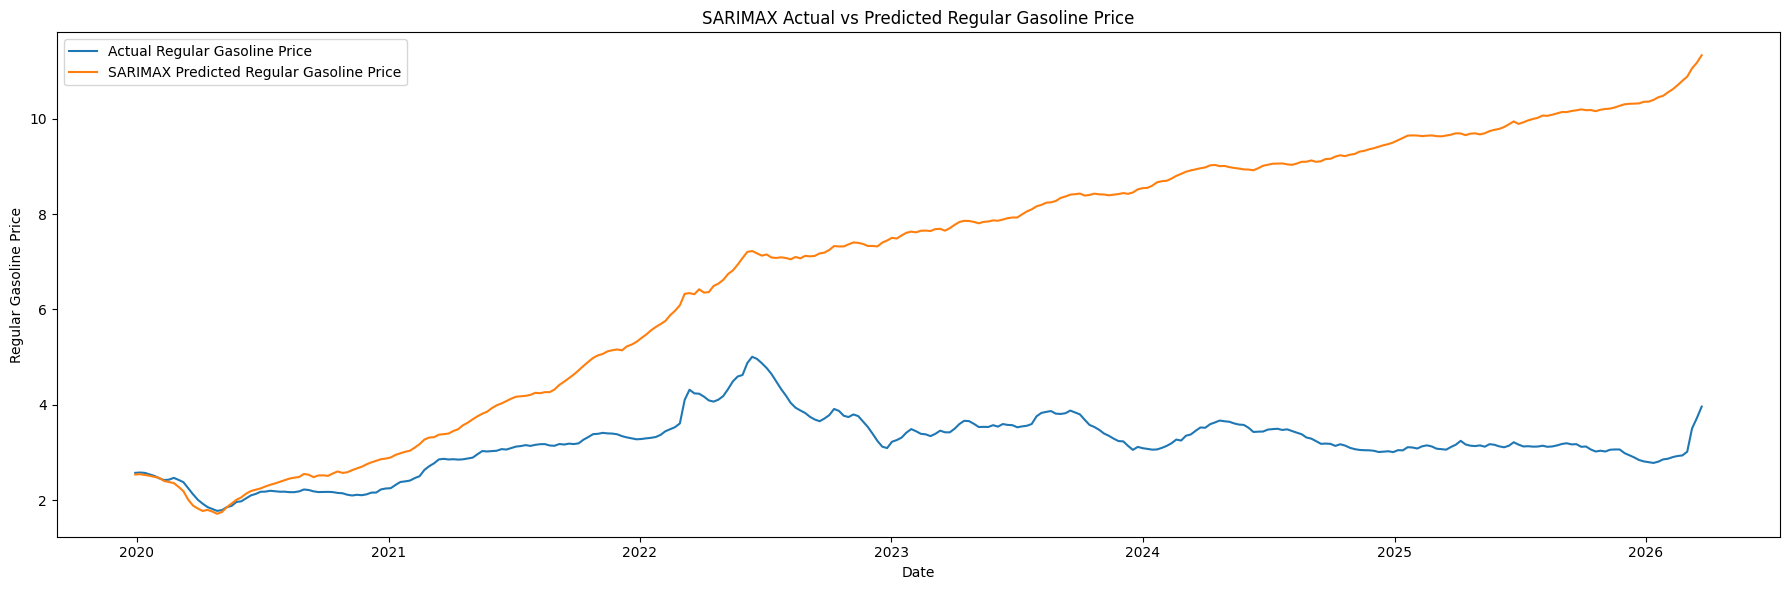

In [133]:
#Plot the model

plt.figure(figsize=(18, 6))

plt.plot(
    date_test_sarimax,
    y_test,
    label="Actual Regular Gasoline Price"
)

plt.plot(
    date_test_sarimax,
    sarimax_predictions,
    label="SARIMAX Predicted Regular Gasoline Price"
)

plt.xlabel("Date")
plt.ylabel("Regular Gasoline Price")
plt.title("SARIMAX Actual vs Predicted Regular Gasoline Price")
plt.legend()
plt.tight_layout()
plt.show()

>>SARIMAX is not suitable in this current setup for your final model. The prediction line keeps increasing far above the actual gasoline price, which means the model is unstable and not learning the correct gasoline price pattern.

## Summary

This project focused on predicting U.S. regular gasoline prices and identifying the key market factors that influence gasoline price changes. The data was collected from two reliable public sources: Federal Reserve Economic Data (FRED) and the U.S. Energy Information Administration (EIA). FRED was used to collect major economic and oil market indicators, including WTI crude oil, Brent crude oil, Dollar Index, Federal Funds Rate, and CPI. EIA was used to collect weekly gasoline price data, U.S. crude oil stocks, and U.S. crude oil production. Regular gasoline price was selected as the target variable because it is the most common fuel price affecting consumers, transportation companies, delivery businesses, and fuel retailers. After cleaning, converting dates, resampling all datasets to weekly frequency, merging by date, and handling missing values, the final dataset contained 1,630 weekly records and 11 columns with no missing values.

The analysis showed that gasoline prices are strongly connected to crude oil prices, especially Brent crude oil and WTI crude oil, because crude oil is the main raw material used to produce gasoline. However, gasoline prices are also influenced by broader economic and supply-side factors such as inflation, interest rates, U.S. dollar strength, crude oil stocks, crude oil production, seasonal demand, and market conditions. Feature importance analysis from the Random Forest model and SHAP analysis from the XGBoost model both supported this finding. Brent crude oil was the strongest external driver, while CPI and WTI crude oil were also important. This shows that gasoline price changes are mainly driven by crude oil costs, inflation pressure, and broader supply and economic conditions.

Five models were developed because each model answered a different business question. Model 1, Random Forest without lag features, was used as the baseline long-term explanatory model. It predicted gasoline prices using external market and economic variables such as crude oil prices, CPI, Dollar Index, Federal Funds Rate, crude oil stocks, crude oil production, month, and year. To evaluate the models, MAE, RMSE, R², and MAPE were used because each metric explains performance in a different way. MAE shows the average prediction error in dollars per gallon, which is easy to understand from a business perspective. RMSE also measures error in dollars per gallon, but it gives more weight to large mistakes, making it useful for identifying models that miss major price changes. R² shows how much of the gasoline price variation the model can explain, while MAPE shows the average error as a percentage. Together, these metrics provide a balanced view of prediction accuracy, business usefulness, and model reliability.

Model 1 produced an R² of 0.4658, showing that external market and economic variables explained part of the gasoline price movement, but not all of it. Model 2, Random Forest with lag-1 features, was developed for short-term weekly forecasting and performed the best, with MAE 0.0943, RMSE 0.1754, R² 0.9164, and MAPE 2.64%. This strong performance makes business sense because gasoline prices usually move gradually from one week to the next, so the previous week’s price is a very strong predictor. Model 3, XGBoost without lag features, was added as an improved long-term explanatory model. It performed slightly better than Model 1, with MAE 0.3742, RMSE 0.4213, R² 0.5177, and MAPE 11.30%, showing that XGBoost captured some additional nonlinear relationships from the external market indicators. Overall, Model 2 is good for short-term forecasting, while Model 3 is useful for long-term market explanation without depending on the previous week’s gasoline price.

Two additional time-series models, LSTM and SARIMAX, were also tested to see whether they could improve the lag-based forecasting results. The LSTM model was added as an advanced deep learning time-series model because it can learn from multiple previous weeks of data instead of only one lag value. The LSTM captured the overall gasoline price trend, but it smoothed out sharp price peaks and did not perform better than the Random Forest lag-1 model. Its results were MAE 0.2627, RMSE 0.3526, and R² 0.6622. SARIMAX was also tested as a traditional time-series forecasting model with external predictors. However, SARIMAX performed poorly in this project, producing unstable predictions that increased far above the actual gasoline price range and resulted in a negative R² value.

To better understand the factors that actually impact gasoline price changes, the project used both Random Forest feature importance and SHAP feature importance to understand which factors actually influence gasoline price prediction. The Random Forest feature importance plot from Model 1 showed that Brent crude oil was the dominant predictor, followed by WTI crude oil and CPI. This means that, in the baseline no-lag model, gasoline prices were mainly explained by crude oil market prices, especially Brent crude oil. This makes business sense because crude oil is the main input used to produce gasoline, so changes in crude oil prices directly affect gasoline production costs. The SHAP feature importance plot from the XGBoost no-lag model gave a more detailed explanation. It also identified Brent crude oil as the most important factor, followed by CPI and WTI crude oil. This confirms that the strongest drivers of gasoline price changes are crude oil prices and inflation pressure. The SHAP results also showed that month, Federal Funds Rate, crude oil stocks, crude oil production, Dollar Index, and year had smaller but still useful effects. These variables help explain seasonal trends, economic conditions, supply levels, and broader market behavior.

Overall, the project shows that the best model depends on the business purpose. For short-term weekly forecasting, the lag-based Random Forest model is the strongest because gasoline prices usually move gradually from one week to the next. For long-term market explanation, the no-lag models are more useful because they show how external factors such as crude oil prices, inflation, interest rates, dollar strength, crude stocks, and production influence gasoline prices without depending on the previous week’s gasoline price. In business terms, this type of analysis can support fuel budgeting, transportation planning, pricing strategy, inventory decisions, and market risk analysis.

There are also some limitations. First, some economic variables were available at different frequencies, such as daily, weekly, or monthly, so the data had to be resampled and filled to create one weekly dataset. This may reduce some detail in the original data. Second, the model does not include major real-world shock variables such as geopolitical conflicts, OPEC production decisions, refinery shutdowns, natural disasters, regional supply disruptions, or sudden demand changes. These events can cause sharp gasoline price spikes that are difficult for the model to predict. Third, the lag-based model performs very well, but it is mainly useful for short-term forecasting because it depends heavily on the previous week’s gasoline price. Finally, oil and gasoline markets change over time, so the models should be monitored, validated on future data, and retrained regularly to remain accurate. 